In [2]:
print("YouTube Trending Intelligence")
print("Project: YouTube Trending Video Analytics")
print("Status: Ready to begin data analysis!")

YouTube Trending Intelligence
Project: YouTube Trending Video Analytics
Status: Ready to begin data analysis!


In [6]:
import pandas as pd

df = pd.read_csv("Data/INvideos.csv")

df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं..."
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False,Watch Stylish Star Allu Arjun @ ChaySam Weddin...
3,N1vE8iiEg64,17.14.11,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12T07:08:48.000Z,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False,This video showcases the difference between pe...
4,kJzGH0PVQHQ,17.14.11,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13T01:14:16.000Z,"Filmylooks|""latest news""|""telugu movies""|""telu...",464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False,why Samantha became EMOTIONAL @ Samantha naga ...


In [7]:
df.shape

(37352, 16)

In [8]:
df.isnull().sum()

video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               561
dtype: int64

In [9]:
df.duplicated().sum()

4263

In [10]:
df = df.drop_duplicates()

df.shape

(33089, 16)

In [18]:
df["description"] =df["description"].fillna("")

In [19]:
df["description"].isnull().sum()

0

In [20]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [21]:
top_videos = df.sort_values(by="views", ascending=False)

top_videos[["title", "channel_title", "views"]].head(10)

,title,channel_title,views
5408,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,125432237
5119,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,113876217
4936,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,100911567
4477,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,89930713
4236,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,87449453
4013,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,84281319
3823,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,80360459
4743,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,75969469
3639,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,74789251
3456,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,66637636


In [22]:
category_views = df.groupby("category_id")["views"].mean()

category_views = category_views.sort_values(ascending=False)

category_views

category_id
20    3.606369e+06
30    3.191953e+06
10    2.532352e+06
1     2.237283e+06
17    1.846151e+06
15    1.626581e+06
24    9.026280e+05
28    8.428038e+05
26    8.420285e+05
23    8.168136e+05
43    6.649661e+05
22    4.842491e+05
2     3.831783e+05
25    3.522145e+05
19    1.717928e+05
27    1.134839e+05
29    6.284759e+04
Name: views, dtype: float64

In [23]:
import json

with open("Data/IN_category_id.json", "r", encoding="utf-8") as file:
    categories = json.load(file)

print(categories.keys())

dict_keys(['kind', 'etag', 'items'])


In [24]:
category_names = {}

for item in categories["items"]:
    category_id = int(item["id"])
    category_name = item["snippet"]["title"]
    category_names[category_id] = category_name

print(category_names)

{1: 'Film & Animation', 2: 'Autos & Vehicles', 10: 'Music', 15: 'Pets & Animals', 17: 'Sports', 18: 'Short Movies', 19: 'Travel & Events', 20: 'Gaming', 21: 'Videoblogging', 22: 'People & Blogs', 23: 'Comedy', 24: 'Entertainment', 25: 'News & Politics', 26: 'Howto & Style', 27: 'Education', 28: 'Science & Technology', 30: 'Movies', 31: 'Anime/Animation', 32: 'Action/Adventure', 33: 'Classics', 34: 'Comedy', 35: 'Documentary', 36: 'Drama', 37: 'Family', 38: 'Foreign', 39: 'Horror', 40: 'Sci-Fi/Fantasy', 41: 'Thriller', 42: 'Shorts', 43: 'Shows', 44: 'Trailers'}


In [25]:
df["category_id"] = df["category_id"].astype(int)

df["category_name"] = df["category_id"].map(category_names)

category_summary = df.groupby("category_name")["views"].mean()

category_summary = category_summary.sort_values(ascending=False)

category_summary

category_name
Gaming                  3.606369e+06
Movies                  3.191953e+06
Music                   2.532352e+06
Film & Animation        2.237283e+06
Sports                  1.846151e+06
Pets & Animals          1.626581e+06
Entertainment           9.026280e+05
Science & Technology    8.428038e+05
Howto & Style           8.420285e+05
Comedy                  8.168136e+05
Shows                   6.649661e+05
People & Blogs          4.842491e+05
Autos & Vehicles        3.831783e+05
News & Politics         3.522145e+05
Travel & Events         1.717928e+05
Education               1.134839e+05
Name: views, dtype: float64

In [26]:
(category_summary / 1000000).round(2)

category_name
Gaming                  3.61
Movies                  3.19
Music                   2.53
Film & Animation        2.24
Sports                  1.85
Pets & Animals          1.63
Entertainment           0.90
Science & Technology    0.84
Howto & Style           0.84
Comedy                  0.82
Shows                   0.66
People & Blogs          0.48
Autos & Vehicles        0.38
News & Politics         0.35
Travel & Events         0.17
Education               0.11
Name: views, dtype: float64

Matplotlib is building the font cache; this may take a moment.


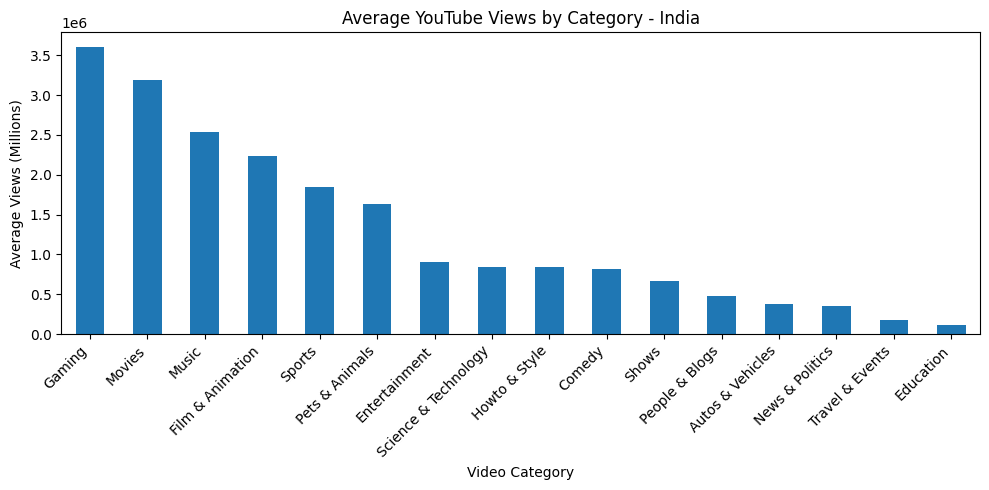

In [27]:
import matplotlib.pyplot as plt

category_summary.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average YouTube Views by Category - India")
plt.xlabel("Video Category")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("visualizations/india_category_average_views.png")
plt.show()

In [28]:
df[["views", "likes", "dislikes", "comment_count"]].describe()

,views,likes,dislikes,comment_count
count,3.308900e+04,3.308900e+04,3.308900e+04,33089.000000
mean,9.963425e+05,2.558762e+04,1.576535e+03,2524.777660
std,3.148111e+06,9.647320e+04,1.689573e+04,14769.825108
min,4.024000e+03,0.000000e+00,0.000000e+00,0.000000
25%,1.127190e+05,7.870000e+02,9.800000e+01,72.000000
50%,2.750270e+05,2.757000e+03,2.890000e+02,298.000000
75%,7.320220e+05,1.201100e+04,9.320000e+02,1169.000000
max,1.254322e+08,2.912710e+06,1.545017e+06,827755.000000


In [29]:
df["engagement_rate"] = (
    (df["likes"] + df["comment_count"]) / df["views"]
) * 100

df[["title", "views", "likes", "comment_count", "engagement_rate"]].head()

,title,views,likes,comment_count,engagement_rate
0,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,1096327,33966,882,3.178614
1,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",590101,735,0,0.124555
2,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,149,0.455708
3,Eruma Saani | Tamil vs English,1242680,70353,2684,5.877378
4,why Samantha became EMOTIONAL @ Samantha naga ...,464015,492,66,0.120255


In [30]:
top_engagement = df.sort_values(
    by="engagement_rate",
    ascending=False
)

top_engagement[
    ["title", "views", "likes", "comment_count", "engagement_rate"]
].head(10)

,title,views,likes,comment_count,engagement_rate
35031,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,840727,321088,329872,77.428226
16612,Oneplus 5T Lava Red Unboxing and Giveaway 🔥🔥🔥 ...,335058,122284,108681,68.932841
35229,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,1049339,355742,367019,68.877741
35445,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,1158291,370533,382685,65.028391
6127,OnePlus 5T Star Wars Limited Edition Unboxing ...,446587,148132,131842,62.691928
26057,Samsung Galaxy S9 Top Features and Tips Tricks...,921731,252602,295139,59.425255
16850,Oneplus 5T Lava Red Unboxing and Giveaway 🔥🔥🔥 ...,446879,131887,118594,56.051191
6318,OnePlus 5T Star Wars Limited Edition Unboxing ...,559686,165108,145754,55.542215
6551,OnePlus 5T Star Wars Limited Edition Unboxing ...,611786,173149,153049,53.318971
5100,Xiaomi Redmi 5A Unboxing & initial impressions...,60209,12706,17221,49.705194


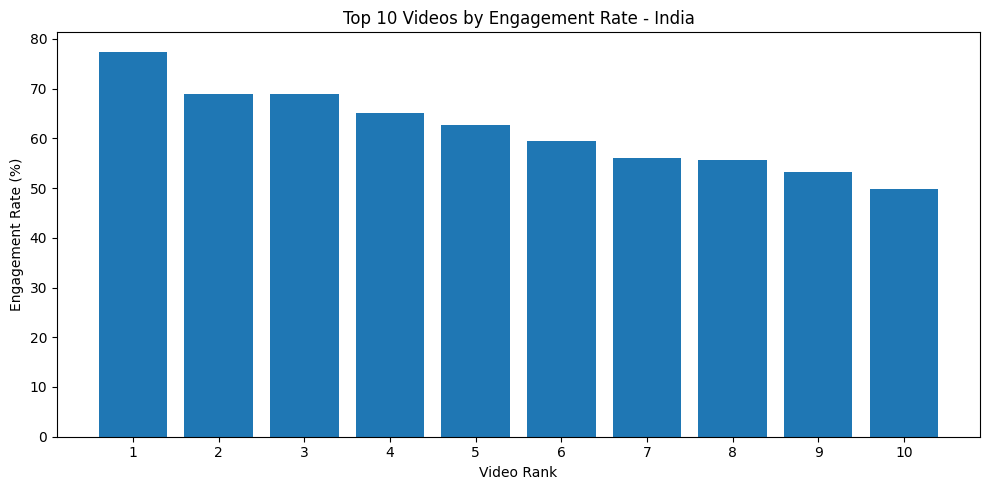

In [31]:
top_10 = top_engagement.head(10)

plt.figure(figsize=(10, 5))
plt.bar(range(1, 11), top_10["engagement_rate"])

plt.title("Top 10 Videos by Engagement Rate - India")
plt.xlabel("Video Rank")
plt.ylabel("Engagement Rate (%)")
plt.xticks(range(1, 11))
plt.tight_layout()

plt.savefig("visualizations/top_10_engagement_rate.png")
plt.show()

In [32]:
category_likes = df.groupby("category_name")["likes"].mean()
category_likes = category_likes.sort_values(ascending=False)

(category_likes / 1000).round(2)

category_name
Pets & Animals          120.84
Gaming                   92.73
Music                    64.72
Comedy                   49.35
Sports                   44.08
Movies                   40.98
Film & Animation         39.50
Science & Technology     35.05
Entertainment            22.23
Howto & Style             9.05
People & Blogs            8.40
Autos & Vehicles          7.09
Education                 5.87
Shows                     3.67
News & Politics           2.86
Travel & Events           2.12
Name: likes, dtype: float64

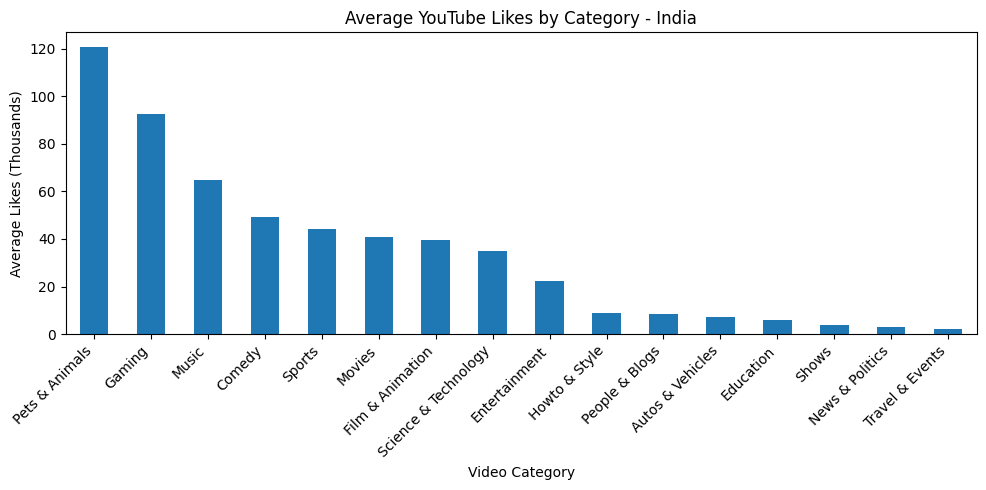

In [34]:
(category_likes / 1000).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average YouTube Likes by Category - India")
plt.xlabel("Video Category")
plt.ylabel("Average Likes (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/india_category_average_likes.png")
plt.show()

In [35]:
category_dislikes = df.groupby("category_name")["dislikes"].mean()
category_dislikes = category_dislikes.sort_values(ascending=False)

(category_dislikes / 1000).round(2)

category_name
Gaming                  4.43
Music                   3.67
Film & Animation        2.49
Movies                  2.19
Pets & Animals          2.16
Comedy                  1.93
Sports                  1.68
Entertainment           1.60
Science & Technology    1.58
Shows                   1.10
Howto & Style           0.97
People & Blogs          0.63
News & Politics         0.49
Autos & Vehicles        0.29
Education               0.19
Travel & Events         0.08
Name: dislikes, dtype: float64

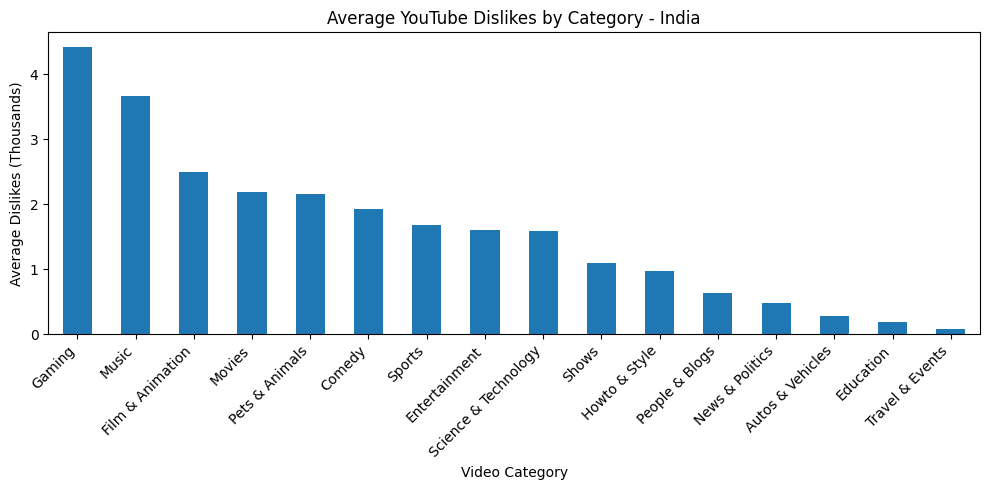

In [36]:
(category_dislikes / 1000).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average YouTube Dislikes by Category - India")
plt.xlabel("Video Category")
plt.ylabel("Average Dislikes (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/india_category_average_dislikes.png")
plt.show()

In [37]:
category_comments = df.groupby("category_name")["comment_count"].mean()
category_comments = category_comments.sort_values(ascending=False)

(category_comments / 1000).round(2)

category_name
Science & Technology    14.66
Pets & Animals          14.02
Gaming                   8.83
Music                    4.42
Comedy                   3.90
Sports                   3.63
Film & Animation         3.31
Entertainment            2.40
Movies                   2.30
Autos & Vehicles         1.25
People & Blogs           0.99
Howto & Style            0.87
Education                0.75
News & Politics          0.54
Shows                    0.52
Travel & Events          0.31
Name: comment_count, dtype: float64

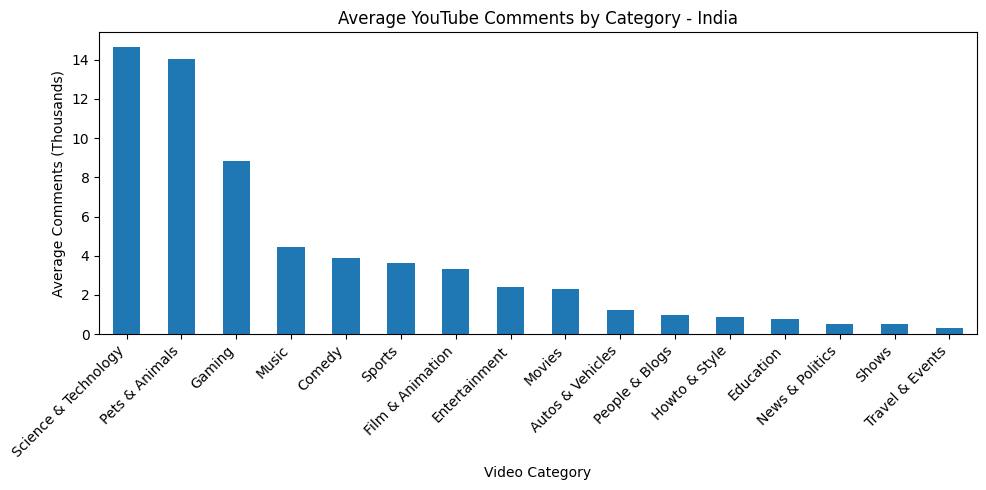

In [38]:
(category_comments / 1000).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average YouTube Comments by Category - India")
plt.xlabel("Video Category")
plt.ylabel("Average Comments (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/india_category_average_comments.png")
plt.show()

In [39]:
top_comments = df.sort_values(
    by="comment_count",
    ascending=False
)

top_comments[
    ["title", "channel_title", "views", "comment_count"]
].head(10)


,title,channel_title,views,comment_count
4743,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,75969469,827755
5408,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,125432237,807558
5119,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,113876217,787174
4568,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,52611730,702784
4936,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,100911567,682890
4459,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24784863,461956
35445,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,Technical Guruji,1158291,382685
33651,Samsung Galaxy J6 Unboxing and Giveaway 🔥🔥🔥,Technical Guruji,2630109,377912
33427,Samsung Galaxy J6 Unboxing and Giveaway 🔥🔥🔥,Technical Guruji,2469042,367354
35229,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,Technical Guruji,1049339,367019


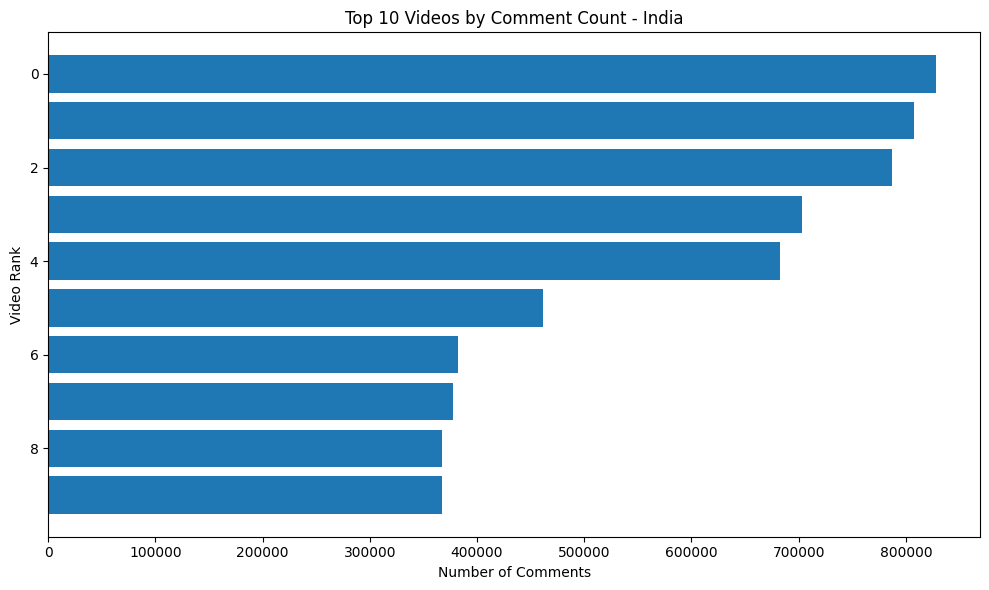

In [40]:
top_10_comments = top_comments.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    range(10),
    top_10_comments["comment_count"]
)

plt.title("Top 10 Videos by Comment Count - India")
plt.xlabel("Number of Comments")
plt.ylabel("Video Rank")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("visualizations/top_10_comment_count.png")
plt.show()

In [41]:
df["trending_date"].value_counts().head(10)

trending_date
17.14.11    200
18.25.01    200
17.13.12    200
17.12.12    200
18.13.01    200
17.18.12    200
18.14.01    200
18.12.01    200
18.20.01    200
18.21.01    200
Name: count, dtype: int64

In [42]:
df["trending_date"].nunique()

205

In [43]:
print("Earliest trending date:", df["trending_date"].min())
print("Latest trending date:", df["trending_date"].max())

Earliest trending date: 17.01.12
Latest trending date: 18.31.05


In [44]:
df["trending_date"] = pd.to_datetime(
    df["trending_date"],
    format="%y.%d.%m"
)

df[["trending_date"]].head()

,trending_date
0,2017-11-14
1,2017-11-14
2,2017-11-14
3,2017-11-14
4,2017-11-14


In [45]:
print("Earliest trending date:", df["trending_date"].min())
print("Latest trending date:", df["trending_date"].max())

Earliest trending date: 2017-11-14 00:00:00
Latest trending date: 2018-06-14 00:00:00


In [46]:
df["publish_time"] = pd.to_datetime(df["publish_time"], errors="coerce")

df["days_to_trend"] = (
    df["trending_date"] - df["publish_time"].dt.tz_localize(None).dt.normalize()
).dt.days

df["days_to_trend"].describe()

count    33089.000000
mean         2.109734
std          2.155877
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        221.000000
Name: days_to_trend, dtype: float64

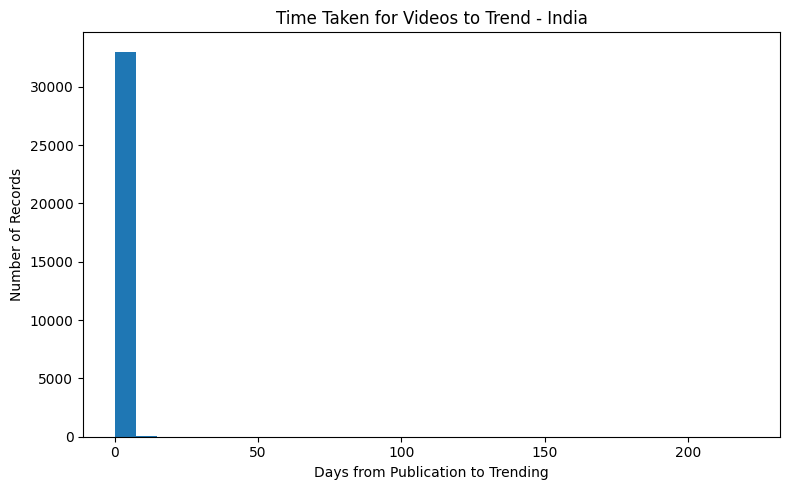

In [47]:
plt.figure(figsize=(8, 5))

plt.hist(df["days_to_trend"], bins=30)

plt.title("Time Taken for Videos to Trend - India")
plt.xlabel("Days from Publication to Trending")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig("visualizations/india_days_to_trend.png")
plt.show()

In [48]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [49]:
df.shape

(33089, 19)

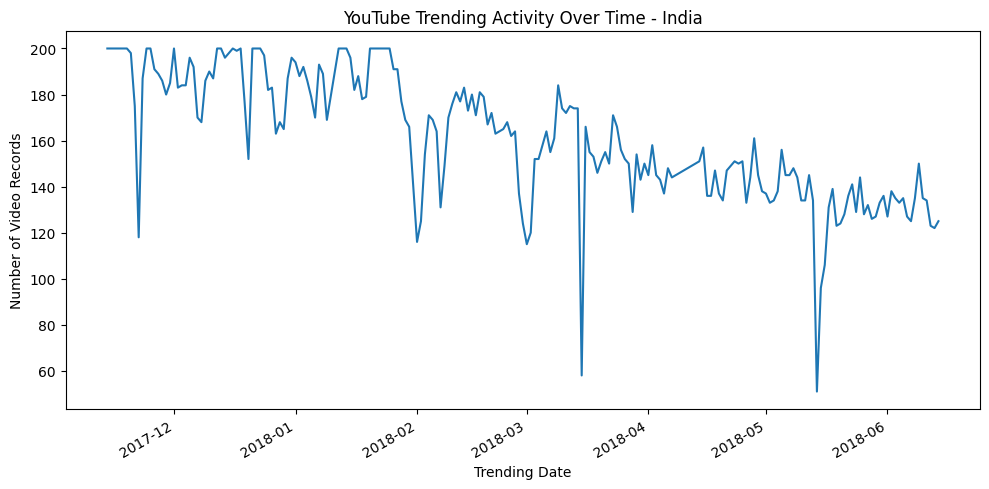

In [50]:
daily_trending = df.groupby("trending_date")["video_id"].count()

daily_trending.plot(figsize=(10, 5))

plt.title("YouTube Trending Activity Over Time - India")
plt.xlabel("Trending Date")
plt.ylabel("Number of Video Records")
plt.tight_layout()

plt.savefig("visualizations/india_trending_over_time.png")
plt.show()

In [51]:
df["category_name"].value_counts().head(10)

category_name
Entertainment           14764
News & Politics          4709
Music                    3292
Comedy                   2967
People & Blogs           2367
Film & Animation         1463
Education                1166
Howto & Style             801
Sports                    646
Science & Technology      517
Name: count, dtype: int64

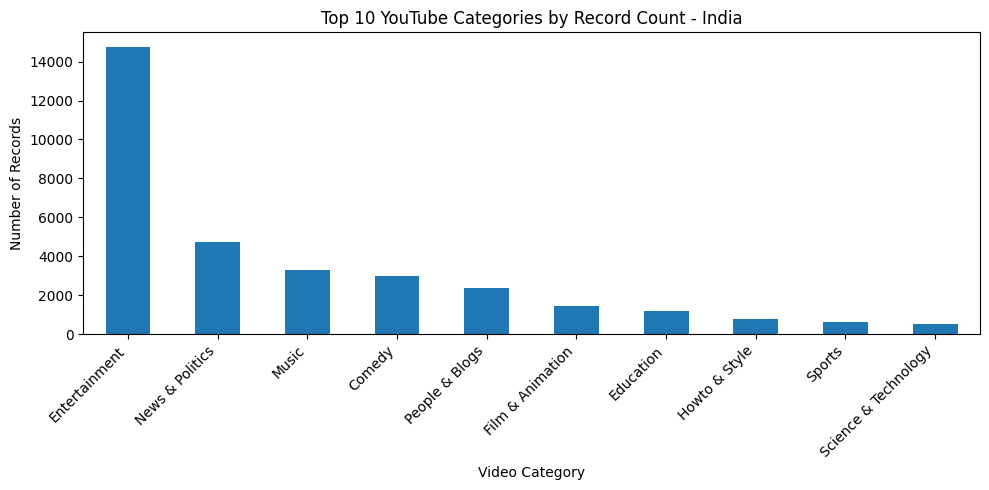

In [52]:
category_counts = df["category_name"].value_counts().head(10)

category_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 YouTube Categories by Record Count - India")
plt.xlabel("Video Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/india_top_10_categories.png")
plt.show()

In [53]:
df["title_length"] = df["title"].str.len()

df[["title", "title_length"]].sort_values(
    by="title_length", ascending=False
).head(10)

,title,title_length
9868,"7 जनवरी 2018 को शनिदेव होंगे उदय,5 राशियों को ...",100
5953,Aana Alaralodalaral Official Trailer | Vineeth...,100
17023,കണ്ണിറുക്കിയും ചുംബനമെയ്‌‌തും പ്രിയയും റോഷനും ...,100
31628,जब घर में कोई भी सब्ज़ी न हो तो बनाये ये स्वादि...,100
21960,Vasishta Talks About Flirting With Manvitha | ...,100
31613,"देखिए जब चीते की रफ्तार से दौड़ने धोनी,फिर गें...",100
21963,Guru Randhawa & Coach Himesh Sings Aashiqui Me...,100
5506,విజయ్ చావు గురించి అత్త - కోడలు వాదనలు చూడండి-...,100
17000,പ്രിയയെ പറ്റി വിജയ് പറഞ്ഞ തമാശ വൈറലാകുന്നു| Il...,100
5509,విజయ్ సెల్ఫీ వీడియోలో బయటపెట్టిన నిజాలు | Come...,100


In [54]:
df["title_length"].mean()

70.94974160597177

In [55]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [56]:
df["title_length"].describe()

count    33089.000000
mean        70.949742
std         22.272010
min          5.000000
25%         54.000000
50%         74.000000
75%         91.000000
max        100.000000
Name: title_length, dtype: float64

In [57]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [58]:
df["tag_count"] = df["tags"].apply(
    lambda x: 0 if x == "[none]" else len(x.split("|"))
)

df[["title", "tags", "tag_count"]].head(10)

,title,tags,tag_count
0,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,"sharry mann|""sharry mann new song""|""sharry man...",15
1,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...","पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",19
2,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,14
3,Eruma Saani | Tamil vs English,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",20
4,why Samantha became EMOTIONAL @ Samantha naga ...,"Filmylooks|""latest news""|""telugu movies""|""telu...",11
5,"MCA (Middle Class Abbayi) TEASER - Nani,Sai Pa...","Nenu Local|""Nenu Local Telugu Movie""|""Nani""|""S...",22
6,Daang ( Full Video ) | Mankirt Aulakh | Sukh S...,"punjabi songs|""punjabi bhangra""|""punjabi music...",18
7,Padmavati : Ek Dil Ek Jaan Video Song | Deepik...,"Ek Dil Ek Jaan Video Song|""'Ek Dil Ek Jaan'""|""...",26
8,Chiranjeevi in Naga Chaitanya - Samantha Recep...,Chiranjeevi in Naga Chaitanya - Samantha Recep...,21
9,New bike vs Old bike - the reality,"Jump cuts|""Jumpcuts""|""Tamil comedy""|""Tamil Com...",23


In [59]:
df["tag_count"].describe()

count    33089.000000
mean        18.618937
std         10.016361
min          0.000000
25%         11.000000
50%         18.000000
75%         25.000000
max         72.000000
Name: tag_count, dtype: float64

In [60]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [61]:
df["tag_group"] = pd.cut(
    df["tag_count"],
    bins=[-1, 10, 20, 30, 100],
    labels=["0–10 tags", "11–20 tags", "21–30 tags", "31+ tags"]
)

tag_views = df.groupby("tag_group", observed=False)["views"].mean()

(tag_views / 1000000).round(2)

tag_group
0–10 tags     0.61
11–20 tags    0.95
21–30 tags    1.29
31+ tags      1.12
Name: views, dtype: float64

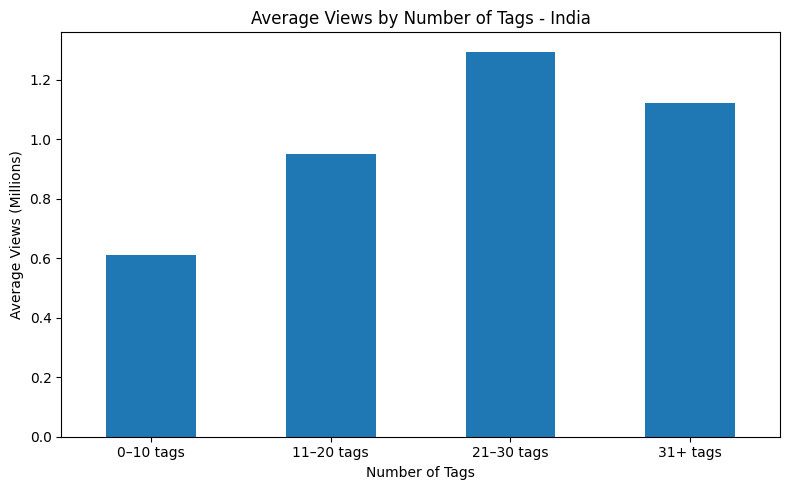

In [63]:
import matplotlib.pyplot as plt

(tag_views / 1000000).plot(kind="bar", figsize=(8, 5))

plt.title("Average Views by Number of Tags - India")
plt.xlabel("Number of Tags")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/india_tag_count_vs_views.png")
plt.show()


In [64]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [65]:
df["title_length_group"] = pd.cut(
    df["title_length"],
    bins=[0, 30, 60, 90, 101],
    labels=["Short (1–30)", "Medium (31–60)", "Long (61–90)", "Very Long (91–100)"],
    include_lowest=True
)

title_views = df.groupby(
    "title_length_group", observed=False
)["views"].mean()

(title_views / 1000000).round(2)

title_length_group
Short (1–30)          1.80
Medium (31–60)        1.21
Long (61–90)          0.77
Very Long (91–100)    0.97
Name: views, dtype: float64

In [66]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [67]:
df["trend_speed"] = pd.cut(
    df["days_to_trend"],
    bins=[-1, 0, 2, 7, 1000],
    labels=["Same day", "1–2 days", "3–7 days", "Over 7 days"]
)

trend_speed_summary = df.groupby(
    "trend_speed", observed=False
).agg(
    video_records=("video_id", "count"),
    average_views=("views", "mean")
)

trend_speed_summary["average_views_millions"] = (
    trend_speed_summary["average_views"] / 1000000
).round(2)

trend_speed_summary

,video_records,average_views,average_views_millions
trend_speed,,,
Same day,441,1.973777e+05,0.20
1–2 days,22898,5.367865e+05,0.54
3–7 days,9686,2.066018e+06,2.07
Over 7 days,64,9.033506e+06,9.03


In [68]:
df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [69]:
top_views = df.nlargest(10, "views")[
    ["title", "channel_title", "views", "likes", "comment_count"]
]

top_views

,title,channel_title,views,likes,comment_count
5408,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,125432237,2912710,807558
5119,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,113876217,2811216,787174
4936,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,100911567,2656672,682890
4477,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,89930713,2606663,347982
4236,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,87449453,2584674,341571
4013,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,84281319,2555411,339708
3823,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,80360459,2513102,335920
4743,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,75969469,2251815,827755
3639,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,74789251,2444956,330710
3456,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,66637636,2331352,316185


In [70]:
top_views.to_csv(
    "visualizations/india_top_10_videos.csv",
    index=False
)

In [71]:
cleaned_df = pd.read_csv("Data/INvideos_cleaned.csv")

print("Dataset shape:", cleaned_df.shape)
print("\nColumn names:")
print(cleaned_df.columns.tolist())

Dataset shape: (33089, 24)

Column names:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'category_name', 'engagement_rate', 'days_to_trend', 'title_length', 'tag_count', 'tag_group', 'title_length_group', 'trend_speed']


In [72]:
print(cleaned_df.columns.tolist())

['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'category_name', 'engagement_rate', 'days_to_trend', 'title_length', 'tag_count', 'tag_group', 'title_length_group', 'trend_speed']


In [75]:
cleaned_df.to_csv("Data/INvideos_cleaned.csv", index=False)

In [77]:
us_df = pd.read_csv("Data/USvideos.csv")

print("Original USA dataset shape:", us_df.shape)
print("\nMissing values:")
print(us_df.isnull().sum())
print("\nDuplicate rows:", us_df.duplicated().sum())

Original USA dataset shape: (40949, 16)

Missing values:
video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               570
dtype: int64

Duplicate rows: 48


In [78]:
# Remove duplicate rows
us_df = us_df.drop_duplicates()

# Fill missing descriptions
us_df["description"] = us_df["description"].fillna("")

# Check the cleaned dataset
print("Cleaned USA dataset shape:", us_df.shape)
print("Remaining missing values:", us_df.isnull().sum().sum())
print("Remaining duplicate rows:", us_df.duplicated().sum())

Cleaned USA dataset shape: (40901, 16)
Remaining missing values: 0
Remaining duplicate rows: 0


In [79]:
import json

with open("Data/US_category_id.json", "r", encoding="utf-8") as file:
    us_categories = json.load(file)

us_category_names = {
    int(item["id"]): item["snippet"]["title"]
    for item in us_categories["items"]
}

us_df["category_name"] = us_df["category_id"].map(us_category_names)

print(us_df["category_name"].value_counts().head(10))

category_name
Entertainment           9944
Music                   6467
Howto & Style           4142
Comedy                  3453
People & Blogs          3208
News & Politics         2485
Science & Technology    2397
Film & Animation        2343
Sports                  2172
Education               1655
Name: count, dtype: int64


In [80]:
us_category_views = (
    us_df.groupby("category_name")["views"]
    .mean()
    .sort_values(ascending=False)
)

print((us_category_views / 1000000).round(2))

category_name
Music                    6.20
Film & Animation         3.10
Nonprofits & Activism    2.96
Gaming                   2.61
Entertainment            2.07
Sports                   2.03
People & Blogs           1.53
Comedy                   1.48
Science & Technology     1.45
Autos & Vehicles         1.36
Howto & Style            0.98
Shows                    0.90
Travel & Events          0.86
Pets & Animals           0.83
Education                0.71
News & Politics          0.59
Name: views, dtype: float64


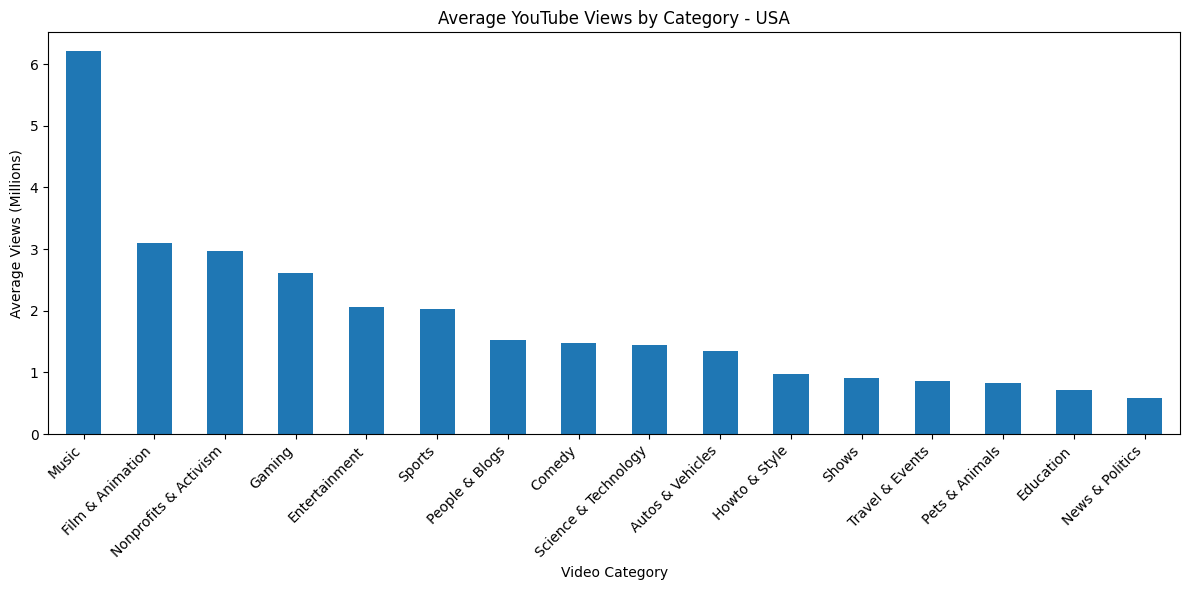

In [81]:
import matplotlib.pyplot as plt

(us_category_views / 1000000).plot(
    kind="bar",
    figsize=(12, 6),
    title="Average YouTube Views by Category - USA"
)

plt.xlabel("Video Category")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/usa_category_average_views.png")
plt.show()

In [82]:
us_df["engagement_rate"] = (
    (us_df["likes"] + us_df["comment_count"]) / us_df["views"]
) * 100

print("Average engagement rate:", round(us_df["engagement_rate"].mean(), 2), "%")

print("\nTop 10 videos by engagement rate:")
print(
    us_df.nlargest(10, "engagement_rate")[
        ["title", "channel_title", "views", "likes", "comment_count", "engagement_rate"]
    ].to_string(index=False)
)

Average engagement rate: 3.89 %

Top 10 videos by engagement rate:
                                                        title      channel_title   views   likes  comment_count  engagement_rate
Bruno Mars - Finesse (Remix) [Feat. Cardi B] [Official Video]         Bruno Mars  548621  159356          19455        32.592810
                                         j-hope 'Airplane' MV            ibighit 5275672 1401915         158127        29.570489
                    Luis Fonsi, Demi Lovato - Échame La Culpa      LuisFonsiVEVO  499946  135292          12094        29.480384
                  5 Seconds Of Summer - Want You Back (Audio)           5SOSVEVO  439056  106536          20575        28.950977
                                   dodie - Secret For The Mad          dodieVEVO  129130   32755           2964        27.661272
                  Louis Tomlinson - Miss You (Official Video) LouisTomlinsonVEVO  985998  241679          26259        27.174294
          BTS (방탄소년단) 'FAKE LO

C:\Users\Guest\AppData\Local\Temp\ipykernel_4916\1266552415.py:14: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from current font.
  plt.tight_layout()
C:\Users\Guest\AppData\Local\Temp\ipykernel_4916\1266552415.py:14: UserWarning: Glyph 53444 (\N{HANGUL SYLLABLE TAN}) missing from current font.
  plt.tight_layout()
C:\Users\Guest\AppData\Local\Temp\ipykernel_4916\1266552415.py:14: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from current font.
  plt.tight_layout()
C:\Users\Guest\AppData\Local\Temp\ipykernel_4916\1266552415.py:14: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from current font.
  plt.tight_layout()
C:\Users\Guest\AppData\Local\Temp\ipykernel_4916\1266552415.py:14: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from current font.
  plt.tight_layout()
C:\Users\Guest\AppData\Local\Temp\ipykernel_4916\1266552415.py:16: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from current font.
  plt.savefig("visuali

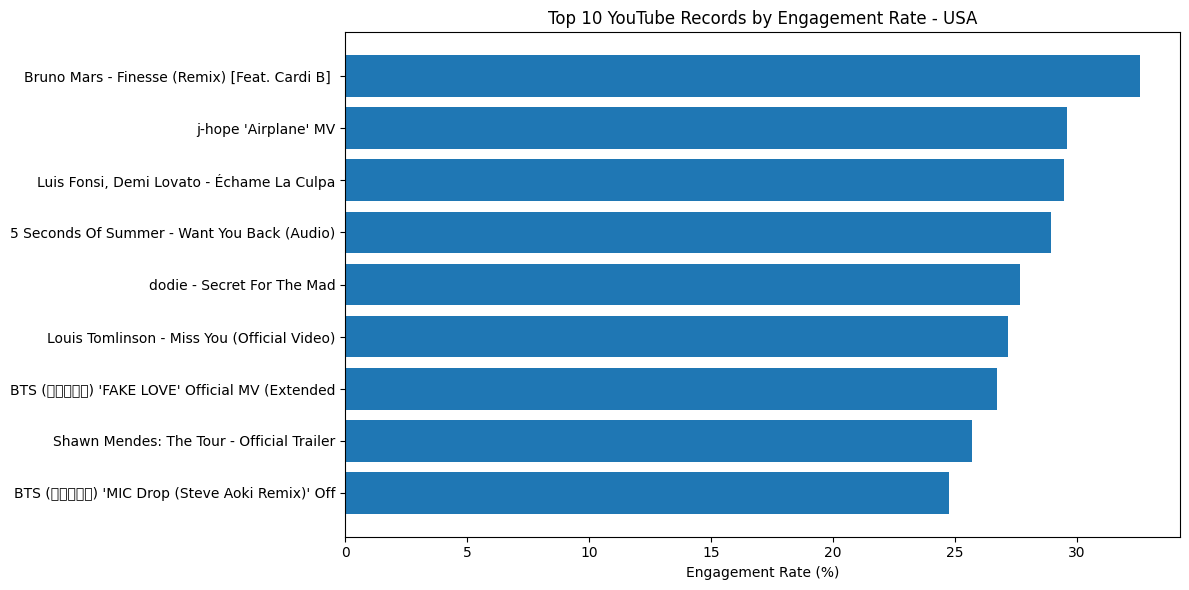

In [83]:
import matplotlib.pyplot as plt

top_us_engagement = us_df.nlargest(10, "engagement_rate")

plt.figure(figsize=(12, 6))
plt.barh(
    top_us_engagement["title"].str.slice(0, 45),
    top_us_engagement["engagement_rate"]
)

plt.xlabel("Engagement Rate (%)")
plt.title("Top 10 YouTube Records by Engagement Rate - USA")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("visualizations/usa_top_10_engagement_rate.png")
plt.show()

In [84]:
us_category_likes = (
    us_df.groupby("category_name")["likes"]
    .mean()
    .sort_values(ascending=False)
)

print((us_category_likes / 1000).round(2))

category_name
Nonprofits & Activism    259.92
Music                    219.05
Gaming                    84.29
Film & Animation          70.68
Comedy                    62.59
People & Blogs            58.09
Entertainment             53.22
Sports                    45.40
Howto & Style             39.24
Science & Technology      34.32
Education                 29.76
Pets & Animals            21.06
Shows                     18.99
Travel & Events           12.03
Autos & Vehicles          11.06
News & Politics            7.30
Name: likes, dtype: float64


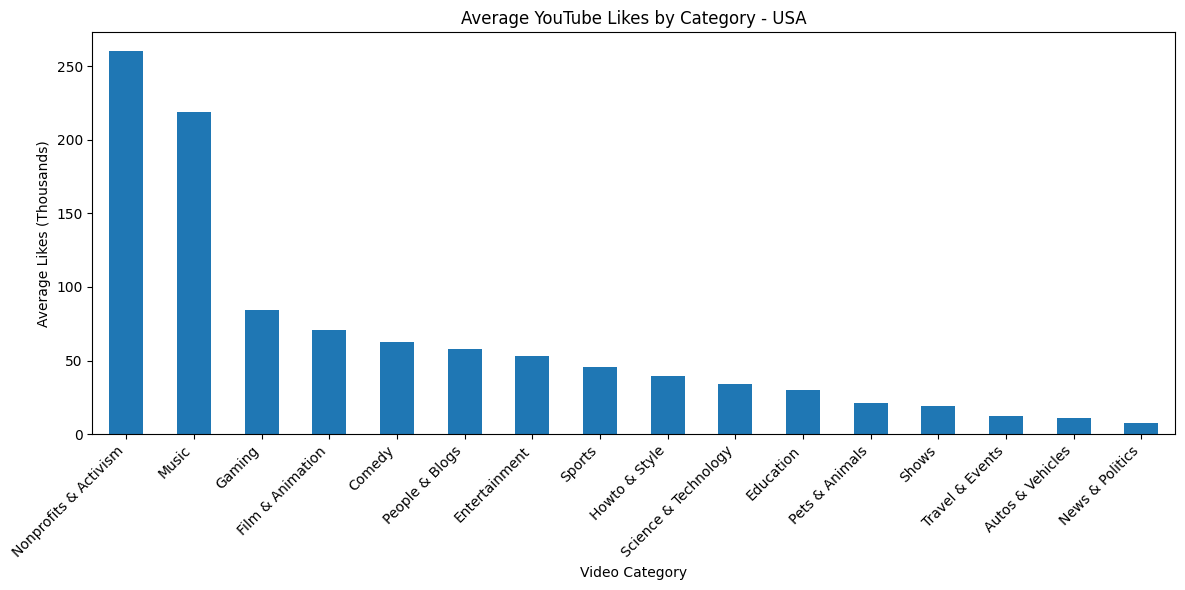

In [85]:
(us_category_likes / 1000).plot(
    kind="bar",
    figsize=(12, 6),
    title="Average YouTube Likes by Category - USA"
)

plt.xlabel("Video Category")
plt.ylabel("Average Likes (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/usa_category_average_likes.png")
plt.show()

In [86]:
us_category_dislikes = (
    us_df.groupby("category_name")["dislikes"]
    .mean()
    .sort_values(ascending=False)
)

print((us_category_dislikes / 1000).round(2))

category_name
Nonprofits & Activism    58.08
Gaming                   11.23
Music                     7.91
Entertainment             4.31
People & Blogs            3.17
Film & Animation          2.59
Sports                    2.36
Comedy                    2.09
Science & Technology      1.89
News & Politics           1.68
Howto & Style             1.32
Travel & Events           0.85
Education                 0.82
Autos & Vehicles          0.63
Pets & Animals            0.57
Shows                     0.43
Name: dislikes, dtype: float64


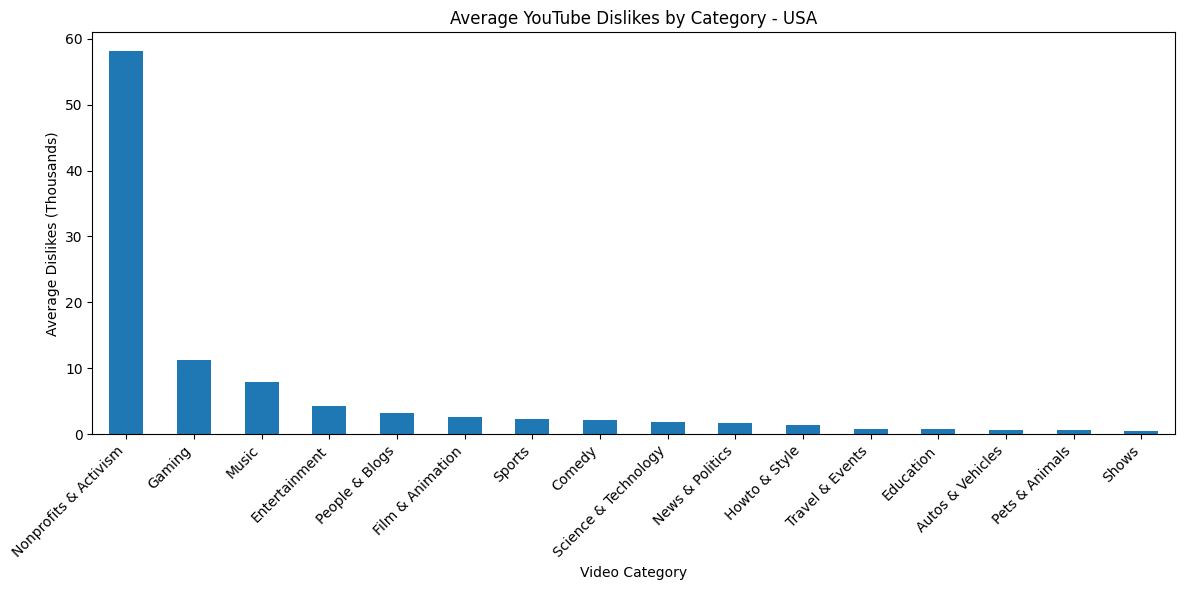

In [87]:
(us_category_dislikes / 1000).plot(
    kind="bar",
    figsize=(12, 6),
    title="Average YouTube Dislikes by Category - USA"
)

plt.xlabel("Video Category")
plt.ylabel("Average Dislikes (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/usa_category_average_dislikes.png")
plt.show()

In [88]:
us_category_comments = (
    us_df.groupby("category_name")["comment_count"]
    .mean()
    .sort_values(ascending=False)
)

print((us_category_comments / 1000).round(2))

category_name
Nonprofits & Activism    84.36
Music                    19.37
Gaming                   18.04
People & Blogs            7.72
Film & Animation          7.63
Entertainment             7.39
Comedy                    6.52
Howto & Style             5.58
Sports                    5.15
Science & Technology      4.99
Education                 3.29
Pets & Animals            2.89
News & Politics           2.43
Travel & Events           2.27
Autos & Vehicles          2.04
Shows                     1.67
Name: comment_count, dtype: float64


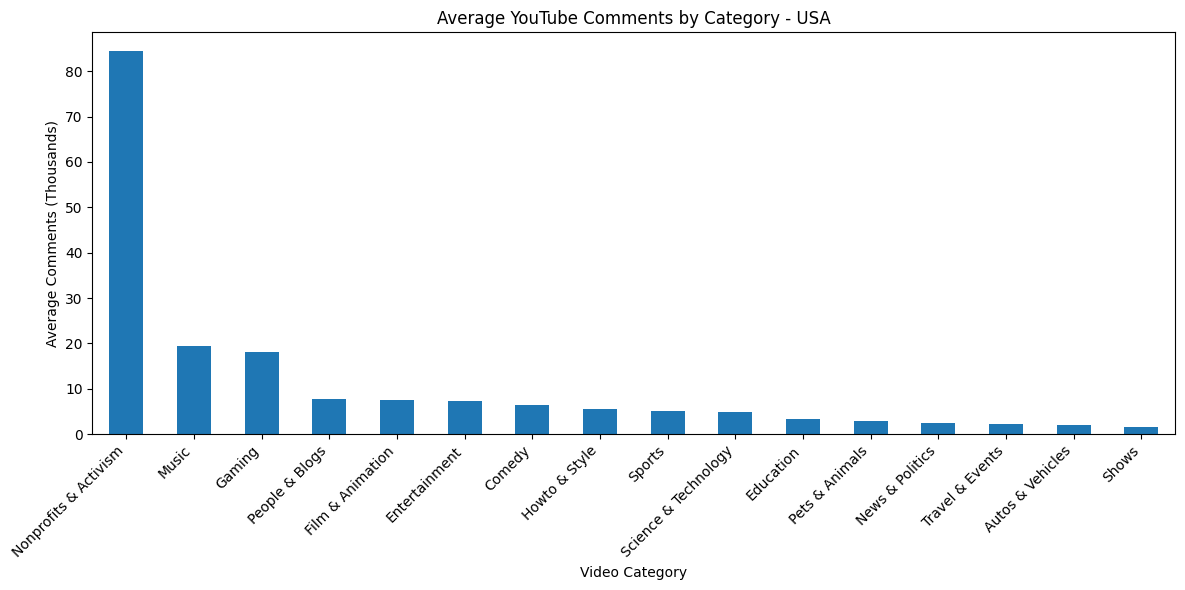

In [89]:
(us_category_comments / 1000).plot(
    kind="bar",
    figsize=(12, 6),
    title="Average YouTube Comments by Category - USA"
)

plt.xlabel("Video Category")
plt.ylabel("Average Comments (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/usa_category_average_comments.png")
plt.show()

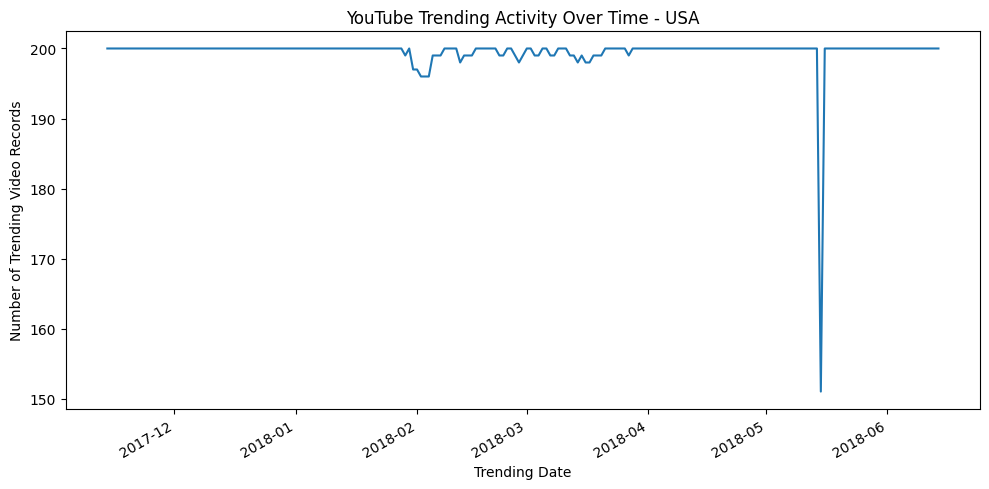

In [90]:
us_df["trending_date"] = pd.to_datetime(
    us_df["trending_date"], format="%y.%d.%m"
)

us_daily_trending = us_df.groupby("trending_date")["video_id"].count()

us_daily_trending.plot(figsize=(10, 5))

plt.title("YouTube Trending Activity Over Time - USA")
plt.xlabel("Trending Date")
plt.ylabel("Number of Trending Video Records")
plt.tight_layout()

plt.savefig("visualizations/usa_trending_over_time.png")
plt.show()

category_name
Entertainment           9944
Music                   6467
Howto & Style           4142
Comedy                  3453
People & Blogs          3208
News & Politics         2485
Science & Technology    2397
Film & Animation        2343
Sports                  2172
Education               1655
Name: count, dtype: int64


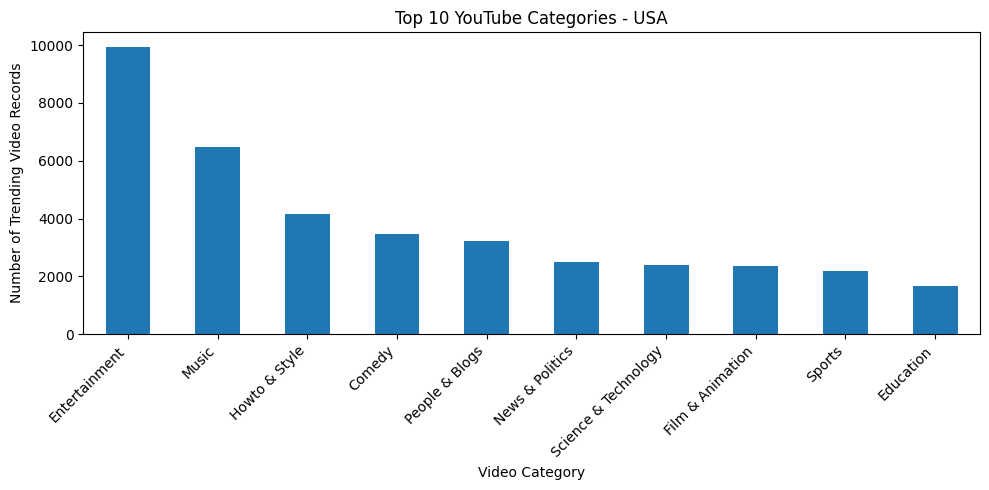

In [91]:
us_top_categories = us_df["category_name"].value_counts().head(10)

print(us_top_categories)

us_top_categories.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 YouTube Categories - USA"
)

plt.xlabel("Video Category")
plt.ylabel("Number of Trending Video Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("visualizations/usa_top_10_categories.png")
plt.show()

In [92]:
us_df["title_length"] = us_df["title"].str.len()

print("Average title length:", round(us_df["title_length"].mean(), 2), "characters")
print("\nTitle length statistics:")
print(us_df["title_length"].describe())

Average title length: 48.58 characters

Title length statistics:
count    40901.000000
mean        48.578617
std         19.621774
min          3.000000
25%         34.000000
50%         46.000000
75%         61.000000
max        100.000000
Name: title_length, dtype: float64


In [93]:
us_df["tag_count"] = us_df["tags"].apply(
    lambda x: 0 if x == "[none]" else len(x.split("|"))
)

print("Average number of tags:", round(us_df["tag_count"].mean(), 2))
print("\nTag count statistics:")
print(us_df["tag_count"].describe())

Average number of tags: 19.69

Tag count statistics:
count    40901.000000
mean        19.694580
std         12.073036
min          0.000000
25%         10.000000
50%         19.000000
75%         29.000000
max         69.000000
Name: tag_count, dtype: float64


Average views by tag count (millions):
tag_group
0–10 tags     2.87
11–20 tags    1.96
21–30 tags    2.55
31+ tags      1.94
Name: views, dtype: float64


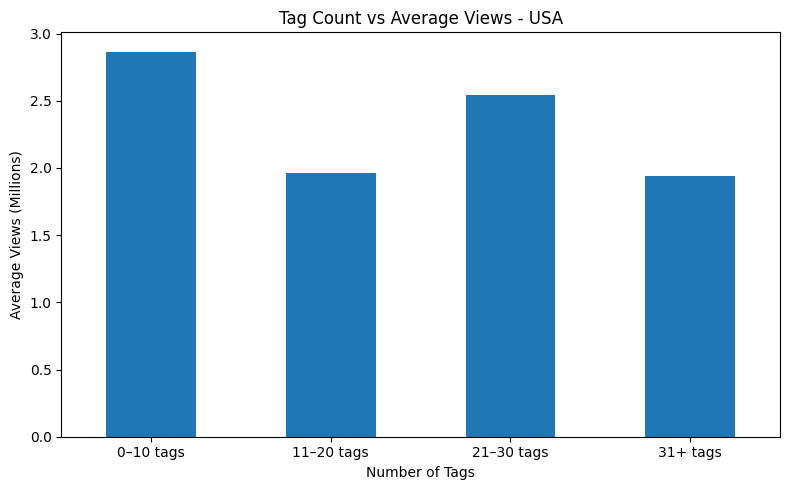

In [94]:
us_df["tag_group"] = pd.cut(
    us_df["tag_count"],
    bins=[-1, 10, 20, 30, 1000],
    labels=["0–10 tags", "11–20 tags", "21–30 tags", "31+ tags"]
)

us_tag_views = us_df.groupby("tag_group", observed=False)["views"].mean() / 1000000

print("Average views by tag count (millions):")
print(us_tag_views.round(2))

us_tag_views.plot(
    kind="bar",
    figsize=(8, 5),
    title="Tag Count vs Average Views - USA"
)

plt.xlabel("Number of Tags")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/usa_tag_count_vs_views.png")
plt.show()

Average views by title length (millions):
title_length_group
Short (1–30)       2.40
Medium (31–60)     2.58
Long (61–90)       1.92
Very Long (91+)    1.42
Name: views, dtype: float64


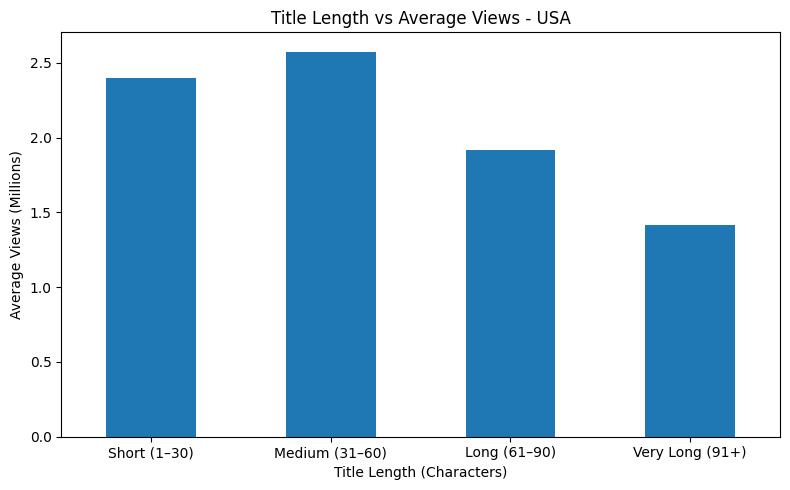

In [95]:
us_df["title_length_group"] = pd.cut(
    us_df["title_length"],
    bins=[0, 30, 60, 90, 1000],
    labels=["Short (1–30)", "Medium (31–60)",
            "Long (61–90)", "Very Long (91+)"]
)

us_title_views = (
    us_df.groupby("title_length_group", observed=False)["views"].mean()
    / 1000000
)

print("Average views by title length (millions):")
print(us_title_views.round(2))

us_title_views.plot(
    kind="bar",
    figsize=(8, 5),
    title="Title Length vs Average Views - USA"
)

plt.xlabel("Title Length (Characters)")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/usa_title_length_vs_views.png")
plt.show()

In [96]:
us_df["publish_time"] = pd.to_datetime(
    us_df["publish_time"], errors="coerce", utc=True
)

us_df["days_to_trend"] = (
    us_df["trending_date"]
    - us_df["publish_time"].dt.tz_convert(None).dt.normalize()
).dt.days

print("Days to trend statistics:")
print(us_df["days_to_trend"].describe())

Days to trend statistics:
count    40901.000000
mean        16.826850
std        146.099164
min          0.000000
25%          3.000000
50%          5.000000
75%          9.000000
max       4215.000000
Name: days_to_trend, dtype: float64


In [97]:
us_df["trend_speed"] = pd.cut(
    us_df["days_to_trend"],
    bins=[-1, 0, 2, 7, 10000],
    labels=["Same day", "1–2 days", "3–7 days", "Over 7 days"]
)

us_trend_summary = us_df.groupby(
    "trend_speed", observed=False
)["views"].agg(["count", "mean"])

us_trend_summary["mean"] = (
    us_trend_summary["mean"] / 1000000
).round(2)

print("USA trending speed summary:")
print(us_trend_summary)

USA trending speed summary:
             count  mean
trend_speed             
Same day       121  0.39
1–2 days      7125  1.01
3–7 days     21062  1.69
Over 7 days  12593  4.26


In [98]:
us_df.to_csv("Data/USvideos_cleaned.csv", index=False)

print("Cleaned USA dataset saved successfully!")
print("Dataset shape:", us_df.shape)

Cleaned USA dataset saved successfully!
Dataset shape: (40901, 24)


In [99]:
gb_df = pd.read_csv("Data/GBvideos.csv")

print("Original GB dataset shape:", gb_df.shape)
print("\nMissing values:")
print(gb_df.isnull().sum().sum())

print("\nDuplicate rows:", gb_df.duplicated().sum())

Original GB dataset shape: (38916, 16)

Missing values:
612

Duplicate rows: 171


In [100]:
gb_df = gb_df.drop_duplicates()
gb_df["description"] = gb_df["description"].fillna("")

print("Cleaned GB dataset shape:", gb_df.shape)
print("Remaining missing values:", gb_df.isnull().sum().sum())
print("Remaining duplicate rows:", gb_df.duplicated().sum())

Cleaned GB dataset shape: (38745, 16)
Remaining missing values: 0
Remaining duplicate rows: 0


In [101]:
import json

with open("Data/GB_category_id.json", "r", encoding="utf-8") as file:
    gb_categories = json.load(file)

gb_category_names = {
    int(item["id"]): item["snippet"]["title"]
    for item in gb_categories["items"]
}

gb_df["category_name"] = gb_df["category_id"].map(gb_category_names)

print("GB category names added successfully!")
print(gb_df[["category_id", "category_name"]].head())

GB category names added successfully!
   category_id    category_name
0           26    Howto & Style
1           24    Entertainment
2           10            Music
3           17           Sports
4           25  News & Politics


Average views by category (millions):
category_name
Music                   12.44
Entertainment            3.27
Film & Animation         3.24
Science & Technology     3.16
Comedy                   2.16
People & Blogs           1.97
Sports                   1.75
Autos & Vehicles         1.49
Shows                    1.43
Travel & Events          1.38
News & Politics          1.14
Pets & Animals           1.01
Gaming                   0.98
Education                0.97
Howto & Style            0.62
Name: views, dtype: float64


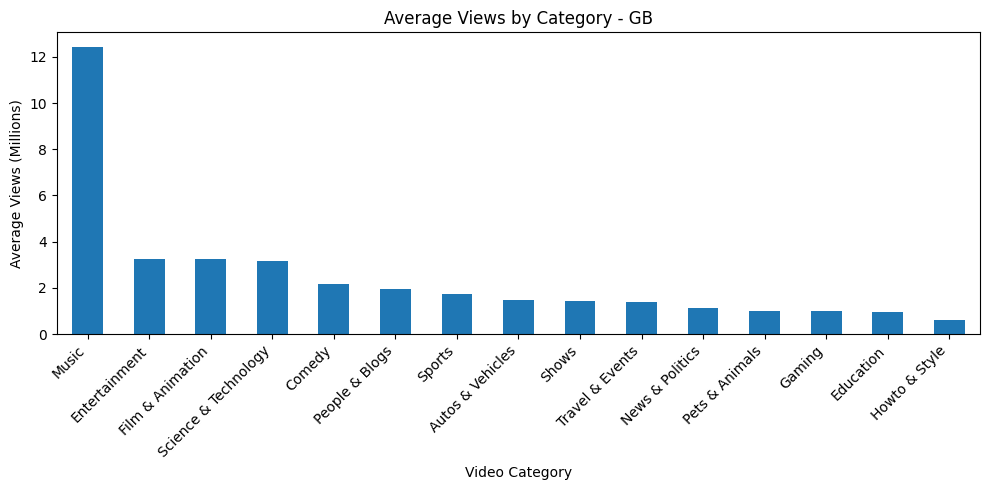

In [102]:
gb_category_views = (
    gb_df.groupby("category_name")["views"]
    .mean()
    .sort_values(ascending=False)
)

print("Average views by category (millions):")
print((gb_category_views / 1000000).round(2))

gb_category_views_millions = gb_category_views / 1000000

gb_category_views_millions.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Views by Category - GB"
)

plt.xlabel("Video Category")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("visualizations/gb_category_average_views.png")
plt.show()

category_name
Music               13700
Entertainment        9055
People & Blogs       2923
Film & Animation     2564
Howto & Style        1928
Sports               1903
Comedy               1820
Gaming               1778
News & Politics      1218
Pets & Animals        533
Name: count, dtype: int64


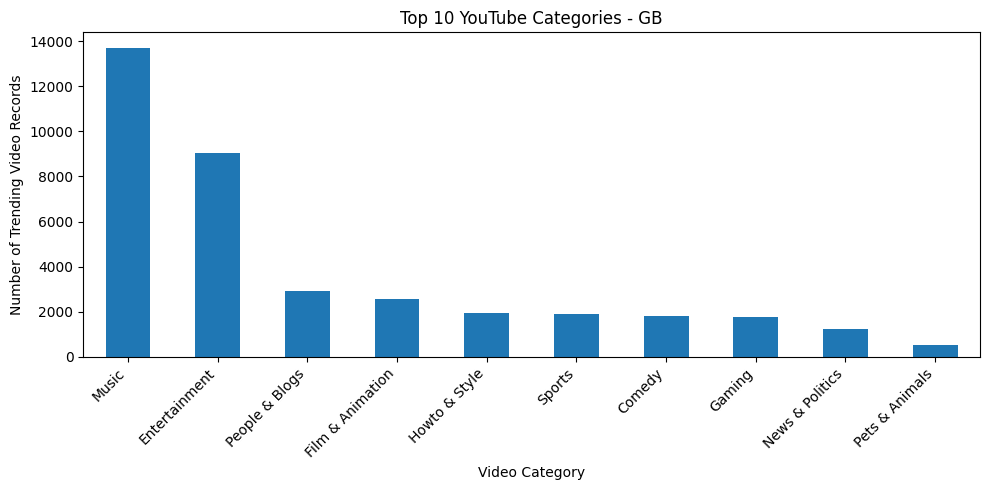

In [103]:
gb_top_categories = gb_df["category_name"].value_counts().head(10)

print(gb_top_categories)

gb_top_categories.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 YouTube Categories - GB"
)

plt.xlabel("Video Category")
plt.ylabel("Number of Trending Video Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("visualizations/gb_top_10_categories.png")
plt.show()

In [104]:
gb_df["engagement_rate"] = (
    (gb_df["likes"] + gb_df["comment_count"]) / gb_df["views"]
) * 100

print("Average Engagement Rate:", round(gb_df["engagement_rate"].mean(), 2), "%")

gb_top_engagement = gb_df.nlargest(10, "engagement_rate")[
    ["title", "channel_title", "engagement_rate"]
]

print(gb_top_engagement)

Average Engagement Rate: 3.8 %
                                                   title  channel_title  \
14615                                         WHAT AM I?      KickThePj   
10198  Bruno Mars - Finesse (Remix) [Feat. Cardi B] [...     Bruno Mars   
22179                               j-hope 'Airplane' MV        ibighit   
14406                         dodie - Secret For The Mad      dodieVEVO   
36395               Gorillaz - Humility (Official Video)       Gorillaz   
19383                   [MIXTAPE] I.M - Fly With Me (MV)     starshipTV   
36739  BTS (방탄소년단) 'FAKE LOVE' Official MV (Extended ...        ibighit   
14818                                         WHAT AM I?      KickThePj   
18207                                 it me ur valentine  doddlevloggle   
22387                               j-hope 'Airplane' MV        ibighit   

       engagement_rate  
14615        33.119729  
10198        31.514490  
22179        29.570584  
14406        27.661272  
36395        27.29

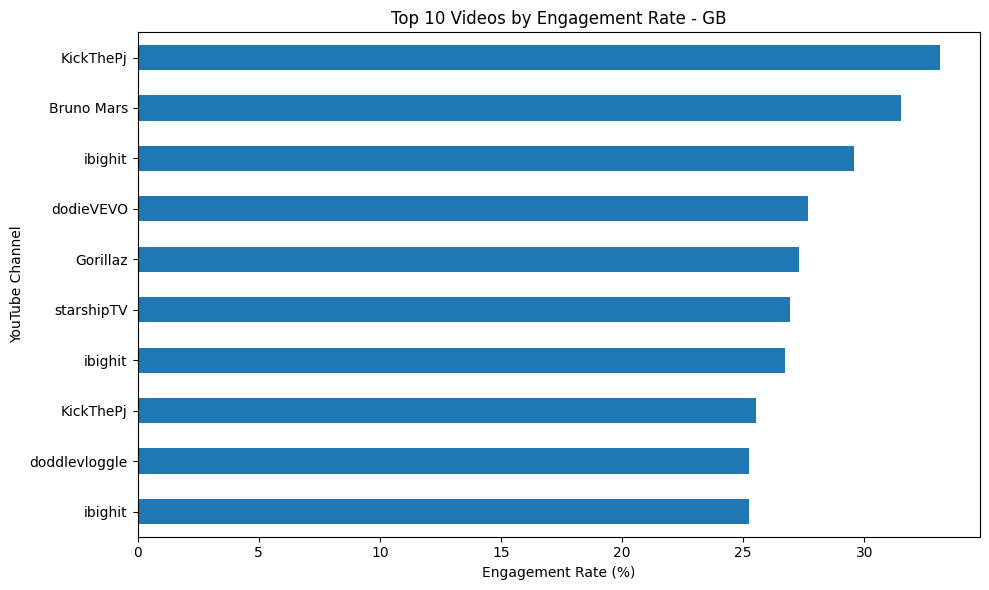

In [105]:
gb_top_engagement.sort_values(
    "engagement_rate"
).plot(
    x="channel_title",
    y="engagement_rate",
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Videos by Engagement Rate - GB",
    legend=False
)

plt.xlabel("Engagement Rate (%)")
plt.ylabel("YouTube Channel")
plt.tight_layout()
plt.savefig("visualizations/gb_top_10_engagement_rate.png")
plt.show()

Average Likes by Category (Thousands):
category_name
Music                   271.83
Entertainment            81.77
Comedy                   78.52
Science & Technology     61.47
Film & Animation         57.16
People & Blogs           46.25
Shows                    41.84
Gaming                   39.36
Sports                   39.32
Education                38.44
Pets & Animals           28.51
Howto & Style            26.64
News & Politics          24.92
Autos & Vehicles         24.61
Travel & Events           9.67
Name: likes, dtype: float64


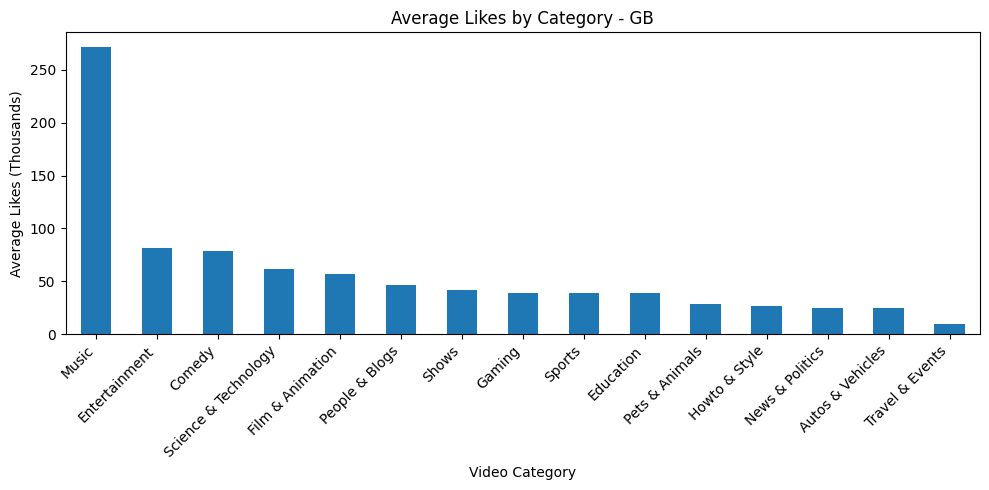

In [106]:
gb_category_likes = (
    gb_df.groupby("category_name")["likes"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Likes by Category (Thousands):")
print((gb_category_likes / 1000).round(2))

(gb_category_likes / 1000).plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Likes by Category - GB"
)

plt.xlabel("Video Category")
plt.ylabel("Average Likes (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("visualizations/gb_category_average_likes.png")
plt.show()

Average Dislikes by Category (Thousands):
category_name
Music                   11.57
Entertainment            9.67
Sports                   5.21
People & Blogs           4.10
Science & Technology     3.13
News & Politics          3.09
Comedy                   2.53
Film & Animation         2.40
Autos & Vehicles         1.95
Education                1.30
Gaming                   1.29
Howto & Style            0.83
Pets & Animals           0.68
Travel & Events          0.36
Shows                    0.32
Name: dislikes, dtype: float64


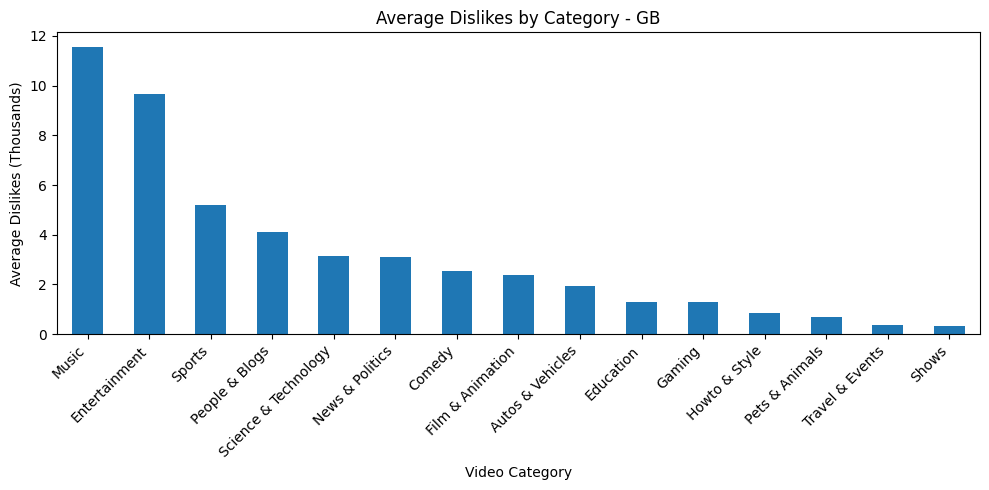

In [107]:
gb_category_dislikes = (
    gb_df.groupby("category_name")["dislikes"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Dislikes by Category (Thousands):")
print((gb_category_dislikes / 1000).round(2))

(gb_category_dislikes / 1000).plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Dislikes by Category - GB"
)

plt.xlabel("Video Category")
plt.ylabel("Average Dislikes (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("visualizations/gb_category_average_dislikes.png")
plt.show()

Average Comments by Category (Thousands):
category_name
Music                   21.26
Entertainment           12.85
Comedy                   9.17
Science & Technology     7.76
News & Politics          7.66
People & Blogs           6.38
Film & Animation         6.05
Sports                   5.28
Shows                    4.05
Howto & Style            3.82
Education                3.58
Autos & Vehicles         3.51
Gaming                   3.46
Pets & Animals           2.62
Travel & Events          1.23
Name: comment_count, dtype: float64


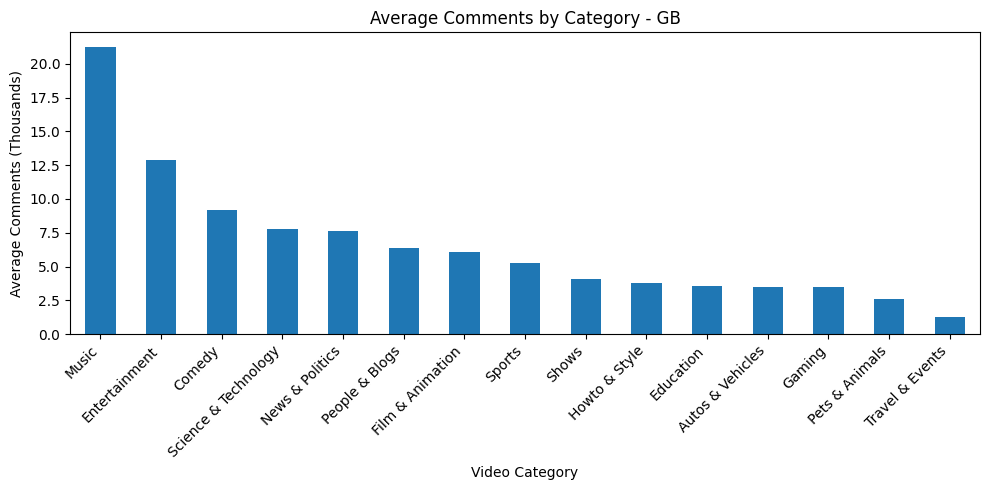

In [108]:
gb_category_comments = (
    gb_df.groupby("category_name")["comment_count"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Comments by Category (Thousands):")
print((gb_category_comments / 1000).round(2))

(gb_category_comments / 1000).plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Comments by Category - GB"
)

plt.xlabel("Video Category")
plt.ylabel("Average Comments (Thousands)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("visualizations/gb_category_average_comments.png")
plt.show()

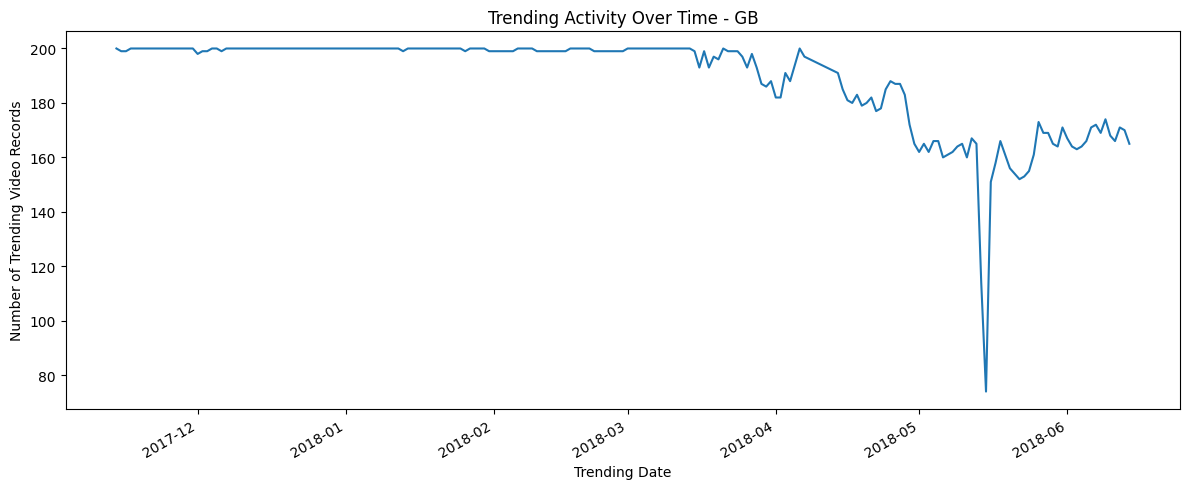

In [109]:
gb_df["trending_date"] = pd.to_datetime(
    gb_df["trending_date"], format="%y.%d.%m"
)

gb_trending_over_time = gb_df.groupby(
    "trending_date"
)["video_id"].count()

gb_trending_over_time.plot(
    figsize=(12, 5),
    title="Trending Activity Over Time - GB"
)

plt.xlabel("Trending Date")
plt.ylabel("Number of Trending Video Records")
plt.tight_layout()
plt.savefig("visualizations/gb_trending_over_time.png")
plt.show()

In [110]:
gb_df["title_length"] = gb_df["title"].str.len()

print("Title Length Statistics:")
print(gb_df["title_length"].describe())

Title Length Statistics:
count    38745.000000
mean        49.526623
std         19.847507
min          6.000000
25%         34.000000
50%         48.000000
75%         62.000000
max        100.000000
Name: title_length, dtype: float64


In [111]:
gb_df["tag_count"] = gb_df["tags"].apply(
    lambda x: 0 if x == "[none]" else len(x.split("|"))
)

print("Tag Count Statistics:")
print(gb_df["tag_count"].describe())

Tag Count Statistics:
count    38745.000000
mean        17.937102
std         12.212468
min          0.000000
25%          8.000000
50%         16.000000
75%         26.000000
max         78.000000
Name: tag_count, dtype: float64


Average Views by Tag Count (Millions):
tag_count_group
0-10 tags     7.08
11-20 tags    5.25
21-30 tags    5.27
31+ tags      5.38
Name: views, dtype: float64


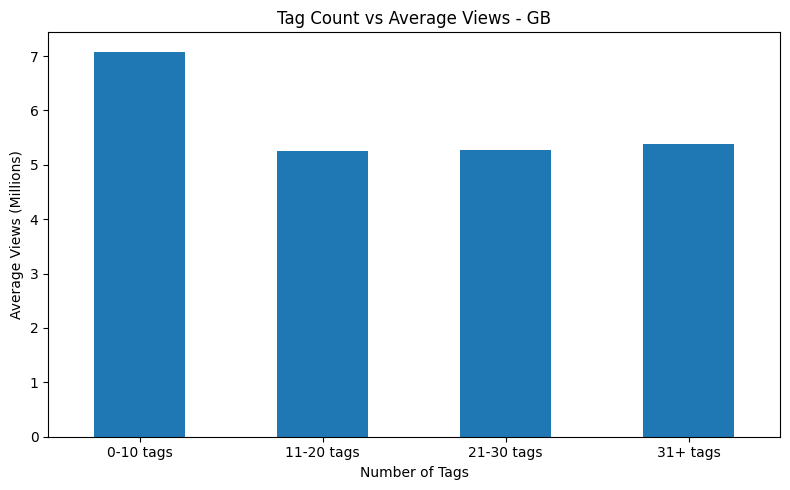

In [112]:
gb_df["tag_count_group"] = pd.cut(
    gb_df["tag_count"],
    bins=[-1, 10, 20, 30, 100],
    labels=["0-10 tags", "11-20 tags", "21-30 tags", "31+ tags"]
)

gb_tag_views = (
    gb_df.groupby("tag_count_group", observed=False)["views"]
    .mean() / 1000000
)

print("Average Views by Tag Count (Millions):")
print(gb_tag_views.round(2))

gb_tag_views.plot(
    kind="bar",
    figsize=(8, 5),
    title="Tag Count vs Average Views - GB"
)

plt.xlabel("Number of Tags")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/gb_tag_count_vs_views.png")
plt.show()

Average Views by Title Length (Millions):
title_length_group
Short (1-30)          7.17
Medium (31-60)        6.33
Long (61-90)          4.46
Very Long (91-100)    2.85
Name: views, dtype: float64


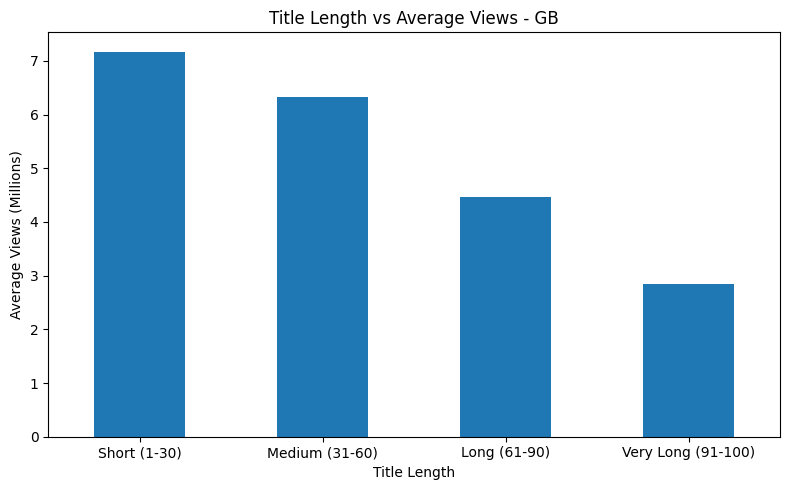

In [113]:
gb_df["title_length_group"] = pd.cut(
    gb_df["title_length"],
    bins=[0, 30, 60, 90, 101],
    labels=["Short (1-30)", "Medium (31-60)",
            "Long (61-90)", "Very Long (91-100)"]
)

gb_title_views = (
    gb_df.groupby("title_length_group", observed=False)["views"]
    .mean() / 1000000
)

print("Average Views by Title Length (Millions):")
print(gb_title_views.round(2))

gb_title_views.plot(
    kind="bar",
    figsize=(8, 5),
    title="Title Length vs Average Views - GB"
)

plt.xlabel("Title Length")
plt.ylabel("Average Views (Millions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/gb_title_length_vs_views.png")
plt.show()

In [114]:
gb_df["publish_time"] = pd.to_datetime(
    gb_df["publish_time"], errors="coerce", utc=True
)

gb_df["days_to_trend"] = (
    gb_df["trending_date"]
    - gb_df["publish_time"].dt.tz_convert(None).dt.normalize()
).dt.days

print("Days to Trend Statistics:")
print(gb_df["days_to_trend"].describe())

Days to Trend Statistics:
count    38745.000000
mean        36.885043
std        241.990782
min          0.000000
25%          6.000000
50%         10.000000
75%         18.000000
max       3990.000000
Name: days_to_trend, dtype: float64


In [115]:
gb_df["trend_speed"] = pd.cut(
    gb_df["days_to_trend"],
    bins=[-1, 0, 2, 7, float("inf")],
    labels=["Same day", "1-2 days", "3-7 days", "Over 7 days"]
)

gb_trend_speed = gb_df.groupby(
    "trend_speed", observed=False
)["views"].mean() / 1000000

print("Average Views by Trend Speed (Millions):")
print(gb_trend_speed.round(2))

Average Views by Trend Speed (Millions):
trend_speed
Same day       0.58
1-2 days       1.40
3-7 days       2.26
Over 7 days    8.11
Name: views, dtype: float64


In [116]:
gb_df.to_csv("Data/GBvideos_cleaned.csv", index=False)
print("Cleaned GB dataset saved successfully!")
print("Dataset shape:", gb_df.shape)

Cleaned GB dataset saved successfully!
Dataset shape: (38745, 24)


In [4]:
import pandas as pd

us_df = pd.read_csv("Data/USvideos_cleaned.csv")

print("USA cleaned dataset loaded!")
print("Shape:", us_df.shape)

USA cleaned dataset loaded!
Shape: (40901, 24)


In [5]:
import sqlite3

conn = sqlite3.connect("YouTube_Trending.db")

us_df.to_sql(
    "USA_Videos",
    conn,
    if_exists="replace",
    index=False
)

print("USA dataset loaded into SQL database!")

USA dataset loaded into SQL database!


In [6]:
query = """
SELECT COUNT(*) AS total_records
FROM USA_Videos;
"""

result = pd.read_sql_query(query, conn)
print(result)

   total_records
0          40901


In [7]:
query = """
SELECT category_name, COUNT(*) AS total_videos
FROM USA_Videos
GROUP BY category_name
ORDER BY total_videos DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result)

          category_name  total_videos
0         Entertainment          9944
1                 Music          6467
2         Howto & Style          4142
3                Comedy          3453
4        People & Blogs          3208
5       News & Politics          2485
6  Science & Technology          2397
7      Film & Animation          2343
8                Sports          2172
9             Education          1655


In [8]:
query = """
SELECT title, channel_title, views
FROM USA_Videos
ORDER BY views DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

                                              title       channel_title     views
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 225211923
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 220490543
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 217750076
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 210338856
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 205643016
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 200820941
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 196222618
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 190950401
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 184446490
Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 179045286


In [9]:
query = """
SELECT video_id, title, channel_title, MAX(views) AS views
FROM USA_Videos
GROUP BY video_id
ORDER BY views DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

   video_id                                                            title        channel_title     views
VYOjWnS4cMY              Childish Gambino - This Is America (Official Video)  ChildishGambinoVEVO 225211923
FlsCjmMhFmw               YouTube Rewind: The Shape of 2017 | #YouTubeRewind    YouTube Spotlight 149376127
ffxKSjUwKdU                             Ariana Grande - No Tears Left To Cry     ArianaGrandeVevo 148689896
zEf423kYfqk             Becky G, Natti Natasha - Sin Pijama (Official Video)           BeckyGVEVO 139334502
7C2z4GqqS5E                              BTS (방탄소년단) 'FAKE LOVE' Official MV              ibighit 123010920
M4ZoCHID9GI                   The Weeknd - Call Out My Name (Official Video)        TheWeekndVEVO 122544931
TyHvyGVs42U                        Luis Fonsi, Demi Lovato - Échame La Culpa        LuisFonsiVEVO 102012605
xTlNMmZKwpA Cardi B, Bad Bunny & J Balvin - I Like It [Official Music Video]              Cardi B  94254507
6ZfuNTqbHE8          Marvel 

In [10]:
query = """
SELECT
    category_name,
    ROUND(AVG(views), 0) AS average_views
FROM USA_Videos
GROUP BY category_name
ORDER BY average_views DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

        category_name  average_views
                Music      6204776.0
     Film & Animation      3101917.0
Nonprofits & Activism      2963884.0
               Gaming      2607598.0
        Entertainment      2067689.0
               Sports      2027262.0
       People & Blogs      1530550.0
               Comedy      1480239.0
 Science & Technology      1449088.0
     Autos & Vehicles      1355965.0
        Howto & Style       982861.0
                Shows       903527.0
      Travel & Events       855612.0
       Pets & Animals       831143.0
            Education       713097.0
      News & Politics       592793.0


In [11]:
query = """
SELECT
    category_name,
    ROUND(AVG(engagement_rate), 2) AS avg_engagement_rate
FROM USA_Videos
GROUP BY category_name
ORDER BY avg_engagement_rate DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

        category_name  avg_engagement_rate
                Music                 5.14
        Howto & Style                 5.09
               Comedy                 4.91
       People & Blogs                 4.66
Nonprofits & Activism                 4.52
               Gaming                 4.48
            Education                 4.23
       Pets & Animals                 3.75
 Science & Technology                 3.48
        Entertainment                 3.24
     Film & Animation                 3.10
                Shows                 2.59
      Travel & Events                 2.44
     Autos & Vehicles                 2.04
      News & Politics                 1.91
               Sports                 1.79


In [12]:
query = """
SELECT
    video_id,
    title,
    channel_title,
    MAX(likes) AS likes
FROM USA_Videos
GROUP BY video_id
ORDER BY likes DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

   video_id                                                           title        channel_title   likes
7C2z4GqqS5E                             BTS (방탄소년단) 'FAKE LOVE' Official MV              ibighit 5613827
VYOjWnS4cMY             Childish Gambino - This Is America (Official Video)  ChildishGambinoVEVO 5023450
ffxKSjUwKdU                            Ariana Grande - No Tears Left To Cry     ArianaGrandeVevo 3094021
FlsCjmMhFmw              YouTube Rewind: The Shape of 2017 | #YouTubeRewind    YouTube Spotlight 3093544
kTlv5_Bs8aw           BTS (방탄소년단) 'MIC Drop (Steve Aoki Remix)' Official MV              ibighit 2729292
p8npDG2ulKQ BTS (방탄소년단) LOVE YOURSELF 轉 Tear 'Singularity' Comeback Trailer              ibighit 2700800
OK3GJ0WIQ8s                                      j-hope 'Daydream (백일몽)' MV              ibighit 2672431
6ZfuNTqbHE8         Marvel Studios' Avengers: Infinity War Official Trailer Marvel Entertainment 2625661
aJOTlE1K90k                           Maroon 5 - Girls 

In [13]:
query = """
SELECT
    category_name,
    ROUND(AVG(comment_count), 0) AS avg_comments
FROM USA_Videos
GROUP BY category_name
ORDER BY avg_comments DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

        category_name  avg_comments
Nonprofits & Activism       84365.0
                Music       19372.0
               Gaming       18040.0
       People & Blogs        7718.0
     Film & Animation        7630.0
        Entertainment        7386.0
               Comedy        6515.0
        Howto & Style        5576.0
               Sports        5152.0
 Science & Technology        4987.0
            Education        3287.0
       Pets & Animals        2892.0
      News & Politics        2429.0
      Travel & Events        2270.0
     Autos & Vehicles        2043.0
                Shows        1669.0


In [14]:
query = """
SELECT
    category_name,
    ROUND(AVG(views), 0) AS avg_views,
    ROUND(AVG(likes), 0) AS avg_likes,
    ROUND(AVG(comment_count), 0) AS avg_comments
FROM USA_Videos
GROUP BY category_name
ORDER BY avg_views DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

        category_name  avg_views  avg_likes  avg_comments
                Music  6204776.0   219046.0       19372.0
     Film & Animation  3101917.0    70681.0        7630.0
Nonprofits & Activism  2963884.0   259924.0       84365.0
               Gaming  2607598.0    84289.0       18040.0
        Entertainment  2067689.0    53221.0        7386.0
               Sports  2027262.0    45403.0        5152.0
       People & Blogs  1530550.0    58089.0        7718.0
               Comedy  1480239.0    62594.0        6515.0
 Science & Technology  1449088.0    34316.0        4987.0
     Autos & Vehicles  1355965.0    11056.0        2043.0
        Howto & Style   982861.0    39236.0        5576.0
                Shows   903527.0    18994.0        1669.0
      Travel & Events   855612.0    12034.0        2270.0
       Pets & Animals   831143.0    21055.0        2892.0
            Education   713097.0    29757.0        3287.0
      News & Politics   592793.0     7299.0        2429.0


In [15]:
query = """
SELECT DISTINCT
    video_id,
    title,
    channel_title,
    views
FROM USA_Videos
WHERE views > 100000000
ORDER BY views DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

   video_id                                                title       channel_title     views
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 225211923
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 220490543
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 217750076
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 210338856
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 205643016
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 200820941
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 196222618
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 190950401
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO 184446490
VYOjWnS4cMY  Childish Gambino - This Is America (O

In [16]:
query = """
SELECT
    video_id,
    title,
    channel_title,
    MAX(views) AS highest_views
FROM USA_Videos
WHERE views > 100000000
GROUP BY video_id
ORDER BY highest_views DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

   video_id                                                title       channel_title  highest_views
VYOjWnS4cMY  Childish Gambino - This Is America (Official Video) ChildishGambinoVEVO      225211923
FlsCjmMhFmw   YouTube Rewind: The Shape of 2017 | #YouTubeRewind   YouTube Spotlight      149376127
ffxKSjUwKdU                 Ariana Grande - No Tears Left To Cry    ArianaGrandeVevo      148689896
zEf423kYfqk Becky G, Natti Natasha - Sin Pijama (Official Video)          BeckyGVEVO      139334502
7C2z4GqqS5E                  BTS (방탄소년단) 'FAKE LOVE' Official MV             ibighit      123010920
M4ZoCHID9GI       The Weeknd - Call Out My Name (Official Video)       TheWeekndVEVO      122544931
TyHvyGVs42U            Luis Fonsi, Demi Lovato - Échame La Culpa       LuisFonsiVEVO      102012605


In [17]:
query = """
SELECT
    channel_title,
    COUNT(DISTINCT video_id) AS total_videos
FROM USA_Videos
GROUP BY channel_title
ORDER BY total_videos DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

                         channel_title  total_videos
                                  ESPN            84
                          TheEllenShow            74
The Tonight Show Starring Jimmy Fallon            72
                     Jimmy Kimmel Live            70
    The Late Show with Stephen Colbert            58
                               Netflix            58
                                   NBA            55
                                   CNN            52
                                   Vox            47
  The Late Late Show with James Corden            46


In [18]:
query = """
SELECT
    category_name,
    ROUND(AVG(views), 0) AS average_views,
    ROUND(AVG(engagement_rate), 2) AS average_engagement
FROM USA_Videos
GROUP BY category_name
ORDER BY average_engagement DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

        category_name  average_views  average_engagement
                Music      6204776.0                5.14
        Howto & Style       982861.0                5.09
               Comedy      1480239.0                4.91
       People & Blogs      1530550.0                4.66
Nonprofits & Activism      2963884.0                4.52
               Gaming      2607598.0                4.48
            Education       713097.0                4.23
       Pets & Animals       831143.0                3.75
 Science & Technology      1449088.0                3.48
        Entertainment      2067689.0                3.24


In [5]:
india_df = pd.read_csv("Data/INvideos_cleaned.csv")

india_df.to_sql(
    "India_Videos",
    conn,
    if_exists="replace",
    index=False
)
print("India dindia_dfataset loaded into SQL database!")
print("India records:", len(india_df))

NameError: name 'pd' is not defined

In [6]:
gb_df = pd.read_csv("Data/GBvideos_cleaned.csv")

gb_df.to_sql(
    "GB_Videos",
    conn,
    if_exists="replace",
    index=False
)

print("Great Britain dataset loaded successfully!")
print("Great Britain records:", len(gb_df))

NameError: name 'pd' is not defined

In [7]:
query = """
SELECT
    'USA' AS country,
    category_name,
    ROUND(AVG(views), 0) AS average_views
FROM USA_Videos
GROUP BY category_name

UNION ALL

SELECT
    'India' AS country,
    category_name,
    ROUND(AVG(views), 0) AS average_views
FROM India_Videos
GROUP BY category_name

UNION ALL

SELECT
    'Great Britain' AS country,
    category_name,
    ROUND(AVG(views), 0) AS average_views
FROM GB_Videos
GROUP BY category_name

ORDER BY category_name, average_views DESC;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

NameError: name 'pd' is not defined

In [22]:
query = """
SELECT country, category_name, average_views
FROM (
    SELECT
        'USA' AS country,
        category_name,
        AVG(views) AS average_views
    FROM USA_Videos
    WHERE category_name IS NOT NULL
    GROUP BY category_name

    UNION ALL

    SELECT
        'India',
        category_name,
        AVG(views)
    FROM India_Videos
    WHERE category_name IS NOT NULL
    GROUP BY category_name

    UNION ALL

    SELECT
        'Great Britain',
        category_name,
        AVG(views)
    FROM GB_Videos
    WHERE category_name IS NOT NULL
    GROUP BY category_name
)
ORDER BY country, average_views DESC;
"""

result = pd.read_sql_query(query, conn)

top_categories = (
    result.groupby("country", sort=False)
    .head(5)
    .copy()
)

top_categories["average_views"] = top_categories["average_views"].round(0)

print(top_categories.to_string(index=False))

      country         category_name  average_views
Great Britain                 Music     12439510.0
Great Britain         Entertainment      3270545.0
Great Britain      Film & Animation      3242571.0
Great Britain  Science & Technology      3158529.0
Great Britain                Comedy      2164341.0
        India                Gaming      3606369.0
        India                Movies      3191953.0
        India                 Music      2532352.0
        India      Film & Animation      2237283.0
        India                Sports      1846151.0
          USA                 Music      6204776.0
          USA      Film & Animation      3101917.0
          USA Nonprofits & Activism      2963884.0
          USA                Gaming      2607598.0
          USA         Entertainment      2067689.0


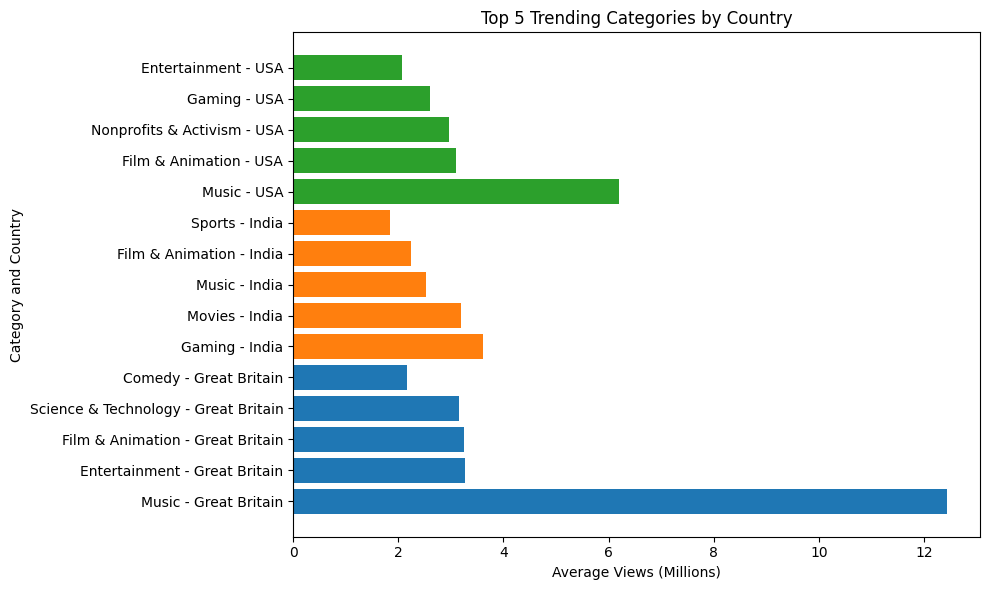

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for country in top_categories["country"].unique():
    data = top_categories[top_categories["country"] == country]
    
    labels = data["category_name"] + " - " + country
    
    plt.barh(labels, data["average_views"] / 1000000)

plt.xlabel("Average Views (Millions)")
plt.ylabel("Category and Country")
plt.title("Top 5 Trending Categories by Country")
plt.tight_layout()

plt.savefig("visualizations/top_categories_country_comparison.png")
plt.show()

In [24]:
query = """
SELECT 'USA' AS country,
       ROUND(AVG(engagement_rate), 2) AS average_engagement_rate
FROM USA_Videos

UNION ALL

SELECT 'India',
       ROUND(AVG(engagement_rate), 2)
FROM India_Videos

UNION ALL

SELECT 'Great Britain',
       ROUND(AVG(engagement_rate), 2)
FROM GB_Videos;
"""

result = pd.read_sql_query(query, conn)
print(result.to_string(index=False))

      country  average_engagement_rate
          USA                     3.89
        India                     2.45
Great Britain                     3.80


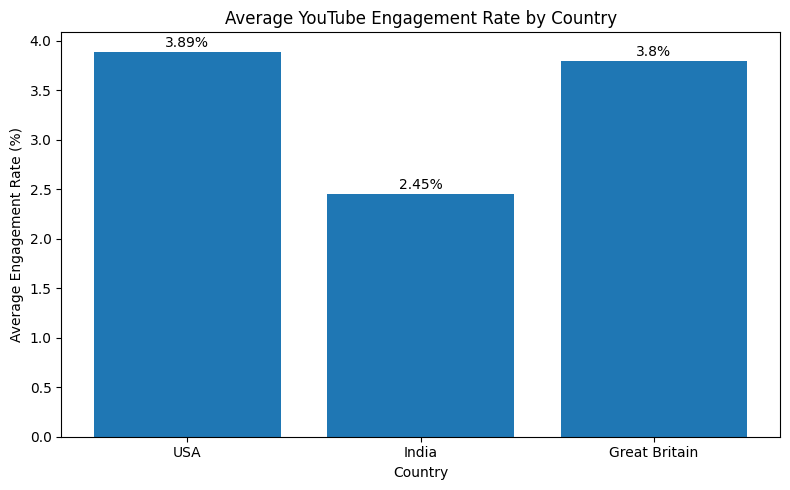

In [25]:
import matplotlib.pyplot as plt

countries = ["USA", "India", "Great Britain"]
engagement_rates = [3.89, 2.45, 3.80]

plt.figure(figsize=(8, 5))
plt.bar(countries, engagement_rates)

plt.xlabel("Country")
plt.ylabel("Average Engagement Rate (%)")
plt.title("Average YouTube Engagement Rate by Country")

for i, value in enumerate(engagement_rates):
    plt.text(i, value + 0.05, str(value) + "%", ha="center")

plt.tight_layout()
plt.savefig("visualizations/country_engagement_comparison.png")
plt.show()

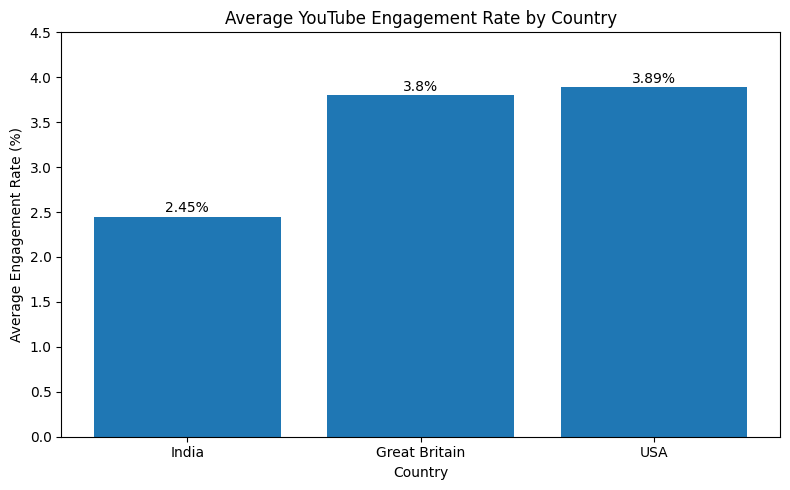

In [26]:
import matplotlib.pyplot as plt

countries = ["India", "Great Britain", "USA"]
engagement_rates = [2.45, 3.80, 3.89]

plt.figure(figsize=(8, 5))

plt.bar(countries, engagement_rates)

plt.xlabel("Country")
plt.ylabel("Average Engagement Rate (%)")
plt.title("Average YouTube Engagement Rate by Country")

for i, value in enumerate(engagement_rates):
    plt.text(i, value + 0.05, str(value) + "%", ha="center")

plt.ylim(0, 4.5)
plt.tight_layout()

plt.savefig("visualizations/country_engagement_comparison.png")
plt.show()

In [27]:
import os

os.makedirs("SQL", exist_ok=True)

print("SQL folder is ready!")

SQL folder is ready!


In [28]:
sql_queries = """
-- YouTube Trending Intelligence
-- Project 4: YouTube Trending Video Analytics

-- 1. Count records in each country
SELECT 'USA' AS country, COUNT(*) AS total_records
FROM USA_Videos
UNION ALL
SELECT 'India', COUNT(*) FROM India_Videos
UNION ALL
SELECT 'Great Britain', COUNT(*) FROM GB_Videos;


-- 2. Top 10 categories by number of trending records in the USA
SELECT category_name, COUNT(*) AS total_records
FROM USA_Videos
WHERE category_name IS NOT NULL
GROUP BY category_name
ORDER BY total_records DESC
LIMIT 10;


-- 3. Average views by category in the USA
SELECT category_name, ROUND(AVG(views), 0) AS average_views
FROM USA_Videos
WHERE category_name IS NOT NULL
GROUP BY category_name
ORDER BY average_views DESC;


-- 4. Average engagement rate by category in the USA
SELECT category_name,
       ROUND(AVG(engagement_rate), 2) AS average_engagement_rate
FROM USA_Videos
WHERE category_name IS NOT NULL
GROUP BY category_name
ORDER BY average_engagement_rate DESC;


-- 5. Top 10 unique videos by maximum views in the USA
SELECT video_id, title, channel_title, MAX(views) AS highest_views
FROM USA_Videos
GROUP BY video_id, title, channel_title
ORDER BY highest_views DESC
LIMIT 10;


-- 6. Average views by category across all three countries
SELECT 'USA' AS country, category_name, ROUND(AVG(views), 0) AS average_views
FROM USA_Videos
WHERE category_name IS NOT NULL
GROUP BY category_name

UNION ALL

SELECT 'India', category_name, ROUND(AVG(views), 0)
FROM India_Videos
WHERE category_name IS NOT NULL
GROUP BY category_name

UNION ALL

SELECT 'Great Britain', category_name, ROUND(AVG(views), 0)
FROM GB_Videos
WHERE category_name IS NOT NULL
GROUP BY category_name;


-- 7. Average engagement rate across all three countries
SELECT 'USA' AS country,
       ROUND(AVG(engagement_rate), 2) AS average_engagement_rate
FROM USA_Videos
UNION ALL
SELECT 'India', ROUND(AVG(engagement_rate), 2)
FROM India_Videos
UNION ALL
SELECT 'Great Britain', ROUND(AVG(engagement_rate), 2)
FROM GB_Videos;
"""

with open("SQL/youtube_analysis_queries.sql", "w", encoding="utf-8") as file:
    file.write(sql_queries)

print("SQL queries saved successfully!")

SQL queries saved successfully!


In [29]:
summary = """
YOUTUBE TRENDING INTELLIGENCE
Project 4: YouTube Trending Video Analytics

DATASETS
- India: 33,089 cleaned records
- USA: 40,901 cleaned records
- Great Britain: 38,745 cleaned records
- Total: 112,735 cleaned records

KEY FINDINGS

1. Most-viewed categories by country:
- India: Gaming, approximately 3.61 million average views.
- USA: Music, approximately 6.20 million average views.
- Great Britain: Music, approximately 12.44 million average views.

2. Average engagement rates:
- India: 2.45%
- Great Britain: 3.80%
- USA: 3.89%

3. Category observations:
- Music performs strongly in the USA and Great Britain.
- Gaming has the highest average views in India.
- Film & Animation is among the top five categories in all three countries.

TOOLS USED
- Python
- Pandas
- Matplotlib
- SQLite and SQL
- Jupyter Notebook

CONCLUSION
The analysis shows differences in trending video categories and
average engagement rates across India, the USA, and Great Britain.
These findings describe the selected historical trending-video
datasets and can help identify patterns in video popularity.
"""

with open("project_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary)

print("Project summary saved successfully!")

Project summary saved successfully!


In [30]:
import os

print("SQL FILE:")
print(os.path.exists("SQL/youtube_analysis_queries.sql"))

print("\nPROJECT SUMMARY:")
print(os.path.exists("project_summary.txt"))

print("\nVISUALIZATION CHARTS:")
for file in os.listdir("visualizations"):
    if file.endswith(".png"):
        print(file)

SQL FILE:
True

PROJECT SUMMARY:
True

VISUALIZATION CHARTS:
country_engagement_comparison.png
gb_category_average_comments.png
gb_category_average_dislikes.png
gb_category_average_likes.png
gb_category_average_views.png
gb_tag_count_vs_views.png
gb_title_length_vs_views.png
gb_top_10_categories.png
gb_top_10_engagement_rate.png
gb_trending_over_time.png
india_category_average_comments.png
india_category_average_dislikes.png
india_category_average_likes.png
india_category_average_views.png
india_days_to_trend.png
india_tag_count_vs_views.png
india_top_10_categories.png
india_trending_over_time.png
top_10_comment_count.png
top_10_engagement_rate.png
top_categories_country_comparison.png
usa_category_average_comments.png
usa_category_average_dislikes.png
usa_category_average_likes.png
usa_category_average_views.png
usa_tag_count_vs_views.png
usa_title_length_vs_views.png
usa_top_10_categories.png
usa_top_10_engagement_rate.png
usa_trending_over_time.png


In [31]:
summary = """
YOUTUBE TRENDING INTELLIGENCE
Project 4: YouTube Trending Video Analytics

DATASETS
- India: 33,089 cleaned records
- USA: 40,901 cleaned records
- Great Britain: 38,745 cleaned records
- Total: 112,735 cleaned records

KEY FINDINGS

1. Most-viewed categories by country:
- India: Gaming, approximately 3.61 million average views.
- USA: Music, approximately 6.20 million average views.
- Great Britain: Music, approximately 12.44 million average views.

2. Average engagement rates:
- India: 2.45%
- Great Britain: 3.80%
- USA: 3.89%

3. Category observations:
- Music performs strongly in the USA and Great Britain.
- Gaming has the highest average views in India.
- Film & Animation is among the top five categories in all three countries.

TOOLS USED
- Python
- Pandas
- Matplotlib
- SQLite and SQL
- Jupyter Notebook

CONCLUSION
The analysis shows differences in trending video categories and
average engagement rates across India, the USA, and Great Britain.
These findings describe the selected historical trending-video
datasets and can help identify patterns in video popularity.
"""

with open("project_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary)

print("Project summary saved successfully!")

Project summary saved successfully!


In [32]:
import os

print("PROJECT FOLDERS AND FILES")
print("-------------------------")

for item in sorted(os.listdir(".")):
    if os.path.isdir(item):
        print("[FOLDER]", item)
    else:
        print("[FILE]", item)

PROJECT FOLDERS AND FILES
-------------------------
[FOLDER] .ipynb_checkpoints
[FOLDER] Dashboard
[FOLDER] Data
[FOLDER] Notebooks
[FOLDER] SQL
[FILE] YouTube_Trending.db
[FILE] Youtube-Trending-Analysis.ipynb
[FILE] project_summary.txt
[FOLDER] visualizations


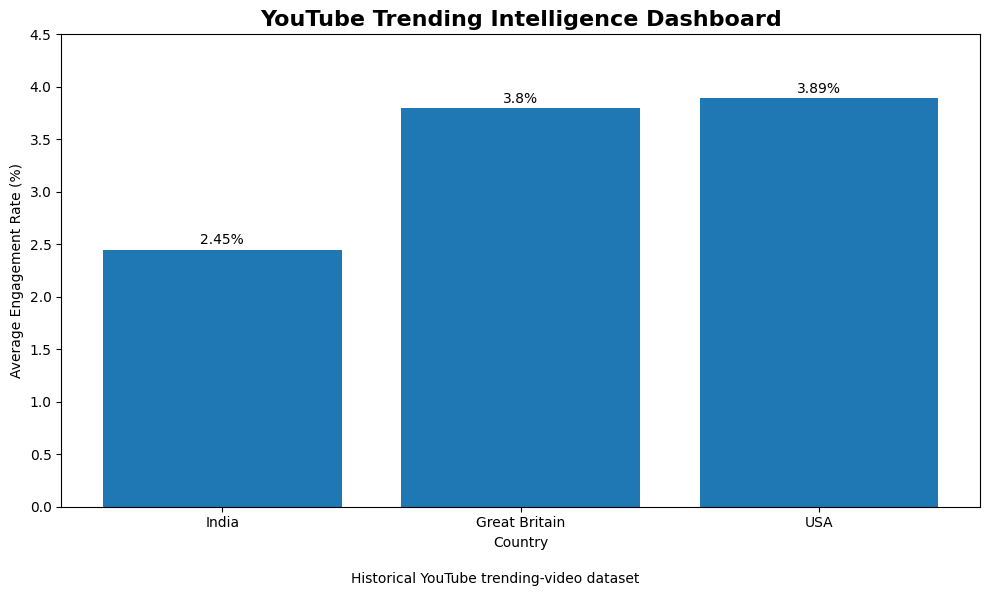

Dashboard saved successfully!


In [34]:
import matplotlib.pyplot as plt
import os

os.makedirs("Dashboard", exist_ok=True)

countries = ["India", "Great Britain", "USA"]
engagement_rates = [2.45, 3.80, 3.89]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(countries, engagement_rates)

ax.set_title("YouTube Trending Intelligence Dashboard",
             fontsize=16, fontweight="bold")
ax.set_xlabel("Country")
ax.set_ylabel("Average Engagement Rate (%)")
ax.set_ylim(0, 4.5)

for bar, value in zip(bars, engagement_rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value}%",
        ha="center"
    )

fig.text(
    0.5, 0.02,
    "Historical YouTube trending-video dataset",
    ha="center"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig("Dashboard/youtube_trending_dashboard.png", dpi=150)
plt.show()

print("Dashboard saved successfully!")

In [35]:
import os

print("FILES INSIDE DASHBOARD FOLDER:")

for file in os.listdir("Dashboard"):
    print(file)

FILES INSIDE DASHBOARD FOLDER:
youtube_trending_dashboard.png


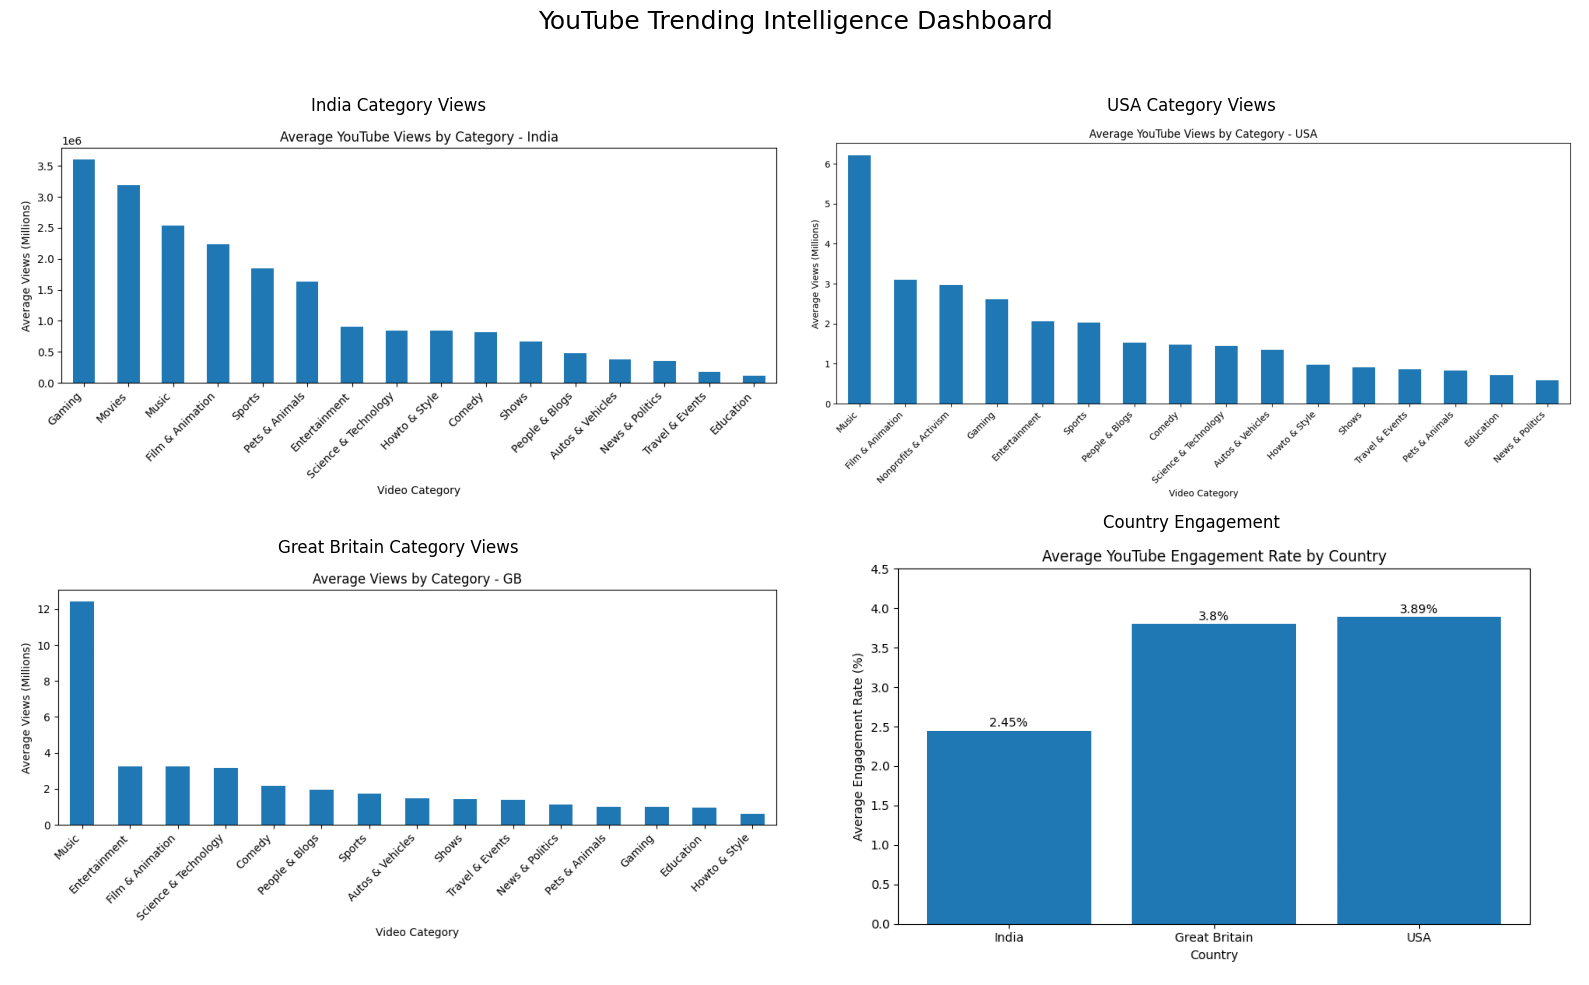

Dashboard PNG saved successfully!


In [36]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

os.makedirs("Dashboard", exist_ok=True)

chart_files = [
    ("India Category Views", "visualizations/india_category_average_views.png"),
    ("USA Category Views", "visualizations/usa_category_average_views.png"),
    ("Great Britain Category Views", "visualizations/gb_category_average_views.png"),
    ("Country Engagement", "visualizations/country_engagement_comparison.png"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("YouTube Trending Intelligence Dashboard", fontsize=18)

for ax, (title, path) in zip(axes.flatten(), chart_files):
    if os.path.exists(path):
        image = mpimg.imread(path)
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
    else:
        ax.set_title(title + " (chart not found)")
        ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    "Dashboard/youtube_trending_dashboard.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Dashboard PNG saved successfully!")

In [37]:
import os

print("Dashboard folder exists:", os.path.exists("Dashboard"))
print("Files inside Dashboard folder:")

for file in os.listdir("Dashboard"):
    print(file)

Dashboard folder exists: True
Files inside Dashboard folder:
.ipynb_checkpoints
youtube_trending_dashboard.png


In [38]:
import os

print("DASHBOARD FOLDER CONTENTS")

for item in os.listdir("Dashboard"):
    path = os.path.join("Dashboard", item)

    if os.path.isfile(path):
        print("FILE:", item)
    else:
        print("FOLDER:", item)

DASHBOARD FOLDER CONTENTS
FOLDER: .ipynb_checkpoints
FILE: youtube_trending_dashboard.png


In [39]:
import shutil

shutil.copy(
    "visualizations/country_engagement_comparison.png",
    "Dashboard/country_engagement_comparison.png"
)

print("Dashboard chart saved successfully!")

Dashboard chart saved successfully!


In [41]:
import os

os.makedirs("Dashboard", exist_ok=True)

dashboard_info = """
YOUTUBE TRENDING INTELLIGENCE
Dashboard and Key Findings

PROJECT:
YouTube Trending Video Analytics

COUNTRIES ANALYSED:
1. India
2. USA
3. Great Britain

KEY FINDINGS:

1. Average views by leading category:
- India: Gaming - 3.61 million views
- USA: Music - 6.20 million views
- Great Britain: Music - 12.44 million views

2. Average engagement rates:
- India: 2.45%
- Great Britain: 3.80%
- USA: 3.89%

3. Main observations:
- Music leads by average views in the USA and Great Britain.
- Gaming leads by average views in India.
- Film & Animation appears among the top five categories
  in all three countries.

VISUALIZATIONS:
The visualizations folder contains charts comparing:
- Average views by category
- Likes, dislikes and comments
- Trending activity over time
- Tag count and title length
- Top categories by country
- Engagement rates across countries

TOOLS:
Python, Pandas, Matplotlib, SQLite and SQL.

NOTE:
These findings are based on the historical datasets used
for this project.
"""

with open("Dashboard/README.txt", "w", encoding="utf-8") as file:
    file.write(dashboard_info)

print("Dashboard README saved successfully!")

Dashboard README saved successfully!


In [1]:
import sqlite3

conn = sqlite3.connect("YouTube_Trending.db")

cursor = conn.cursor()

cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")

tables = cursor.fetchall()

print("Tables in database:", tables)

Tables in database: [('USA_Videos',), ('India_Videos',), ('GB_Videos',)]


In [2]:
for table in ["USA_videos", "India_videos", "GB_videos"]:
    cursor.execute(f"SELECT COUNT(*) FROM {table}")
    count = cursor.fetchone()[0]
    print(f"{table}: {count} rows")

USA_videos: 40901 rows
India_videos: 33089 rows
GB_videos: 38745 rows
